In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
dataset_path = Path(
    r"C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\datasets\NASA_IMS\1st_test"
)

print("Folder exists:", dataset_path.exists())

files = sorted(dataset_path.iterdir())

print("Total files:", len(files))
print("\nFirst 10 files:")

for file in files[:10]:
    print(file.name)

Folder exists: True
Total files: 2156

First 10 files:
2003.10.22.12.06.24
2003.10.22.12.09.13
2003.10.22.12.14.13
2003.10.22.12.19.13
2003.10.22.12.24.13
2003.10.22.12.29.13
2003.10.22.12.34.13
2003.10.22.12.39.13
2003.10.22.12.44.13
2003.10.22.12.49.13


In [5]:
first_file = files[0]

print("File name:", first_file.name)

data = pd.read_csv(
    first_file,
    sep=r"\s+",
    header=None
)

print("\nDataset shape:", data.shape)

print("\nFirst 5 rows:")
display(data.head())

print("\nData types:")
print(data.dtypes)

File name: 2003.10.22.12.06.24

Dataset shape: (20480, 8)

First 5 rows:


,0,1,2,3,4,5,6,7
0,-0.022,-0.039,-0.183,-0.054,-0.105,-0.134,-0.129,-0.142
1,-0.105,-0.017,-0.164,-0.183,-0.049,0.029,-0.115,-0.122
2,-0.183,-0.098,-0.195,-0.125,-0.005,-0.007,-0.171,-0.071
3,-0.178,-0.161,-0.159,-0.178,-0.100,-0.115,-0.112,-0.078
4,-0.208,-0.129,-0.261,-0.098,-0.151,-0.205,-0.063,-0.066



Data types:
0    float64
1    float64
2    float64
3    float64
4    float64
5    float64
6    float64
7    float64
dtype: object


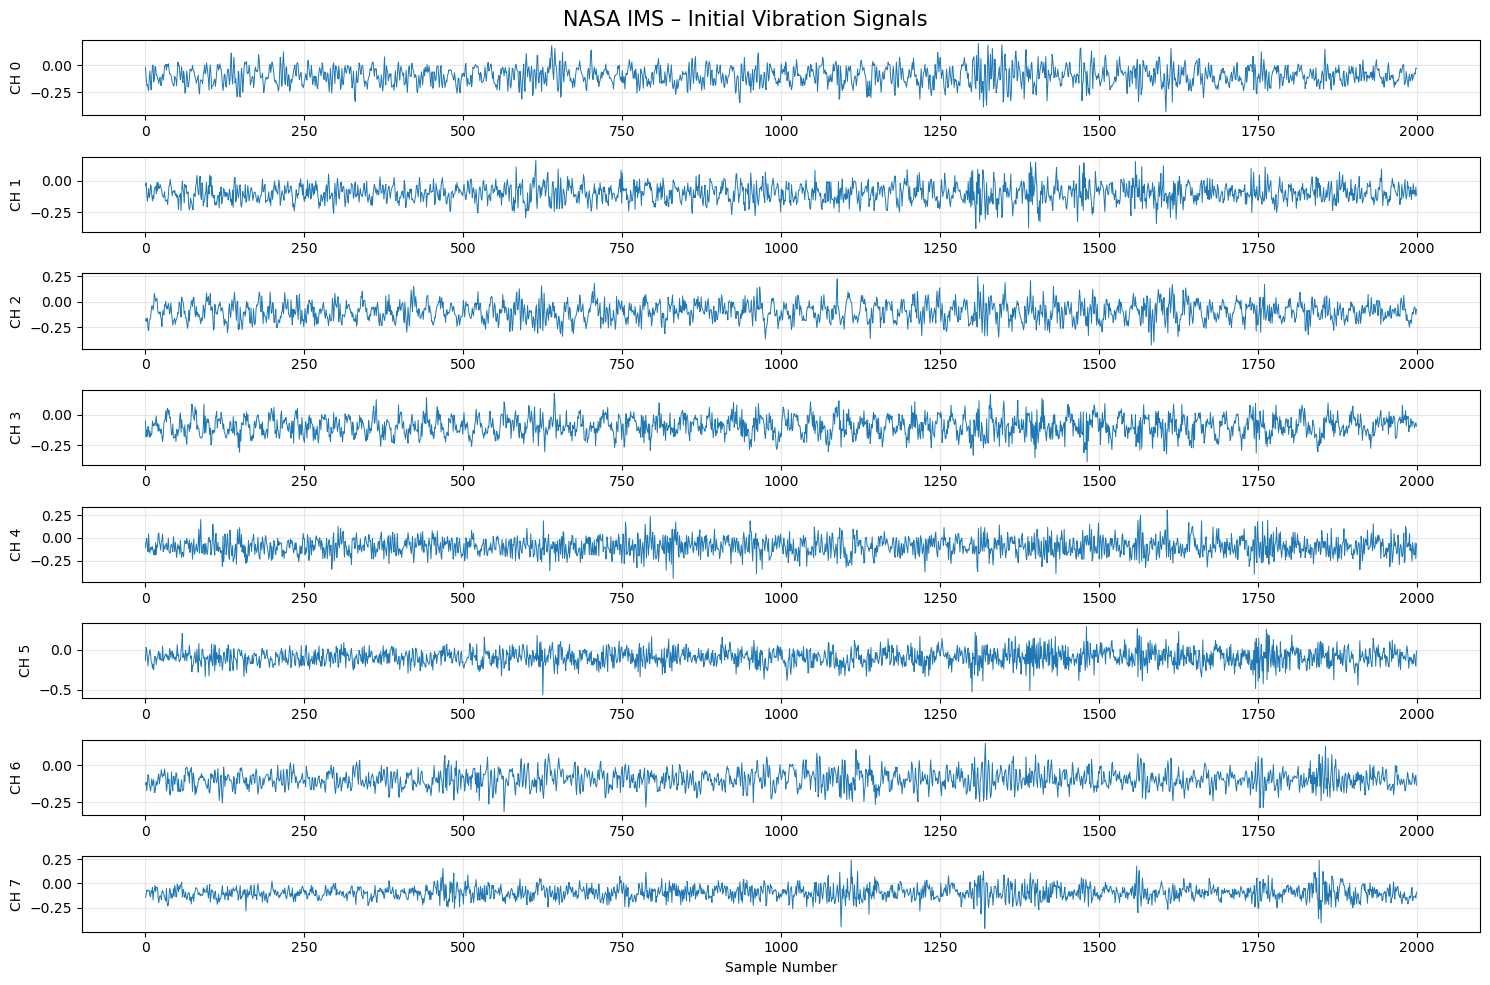

In [7]:
plt.figure(figsize=(15, 10))

for i in range(8):
    plt.subplot(8, 1, i + 1)

    plt.plot(data.iloc[:2000, i], linewidth=0.7)

    plt.ylabel(f"CH {i}")
    plt.grid(True, alpha=0.3)

plt.xlabel("Sample Number")
plt.suptitle("NASA IMS – Initial Vibration Signals", fontsize=15)

plt.tight_layout()
plt.show()

Great! Let's move to the next step: Vibration Feature Extraction.

Before training an RUL model, we need to convert raw vibration signals into meaningful numerical features.

We'll start with five important features:
Feature	What it tells us
Mean	Average vibration value
RMS	Overall vibration energy
Standard Deviation	Signal variation
Kurtosis	Impact / impulsive behaviour
Peak-to-Peak	Difference between maximum and minimum

In [10]:
#Step 7 — Extract features from the first recording
from scipy.stats import kurtosis

def extract_features(signal):

    return {
        "Mean": np.mean(signal),
        "RMS": np.sqrt(np.mean(signal ** 2)),
        "Standard_Deviation": np.std(signal),
        "Kurtosis": kurtosis(signal),
        "Peak_to_Peak": np.ptp(signal)
    }

features = []

for column in data.columns:

    channel_features = extract_features(data[column])

    channel_features["Channel"] = column

    features.append(channel_features)

feature_df = pd.DataFrame(features)

display(feature_df)

,Mean,RMS,Standard_Deviation,Kurtosis,Peak_to_Peak,Channel
0,-0.094593,0.124614,0.081122,1.069163,1.108,0
1,-0.093880,0.117493,0.070648,3.065884,1.265,1
2,-0.093817,0.130455,0.090648,0.209486,1.033,2
3,-0.093752,0.121642,0.077508,0.292221,0.786,3
4,-0.090812,0.128887,0.091461,0.405439,0.896,4
5,-0.090881,0.131821,0.095486,0.777063,1.199,5
6,-0.090969,0.109020,0.060085,0.790250,0.662,6
7,-0.094235,0.115267,0.066380,1.807990,0.845,7


In [12]:
rms_values = []

for file in files:

    temp_data = pd.read_csv(
        file,
        sep=r"\s+",
        header=None
    )

    rms_per_channel = np.sqrt(
        np.mean(temp_data ** 2, axis=0)
    )

    rms_values.append({
        "Timestamp": pd.to_datetime(
            file.name,
            format="%Y.%m.%d.%H.%M.%S"
        ),
        **{
            f"RMS_CH_{i}": rms_per_channel[i]
            for i in range(8)
        }
    })

rms_df = pd.DataFrame(rms_values)

rms_df = rms_df.sort_values("Timestamp").reset_index(drop=True)

display(rms_df.head())

print("Total recordings:", len(rms_df))

,Timestamp,RMS_CH_0,RMS_CH_1,RMS_CH_2,RMS_CH_3,RMS_CH_4,RMS_CH_5,RMS_CH_6,RMS_CH_7
0,2003-10-22 12:06:24,0.124614,0.117493,0.130455,0.121642,0.128887,0.131821,0.109020,0.115267
1,2003-10-22 12:09:13,0.123811,0.116833,0.131490,0.122182,0.129562,0.132049,0.108900,0.109208
2,2003-10-22 12:14:13,0.125246,0.118384,0.131906,0.123572,0.131339,0.133300,0.110319,0.113696
3,2003-10-22 12:19:13,0.125197,0.119005,0.131614,0.122750,0.131083,0.133969,0.111037,0.114413
4,2003-10-22 12:24:13,0.125618,0.119688,0.130779,0.121866,0.131307,0.133281,0.110190,0.114258


Total recordings: 2156


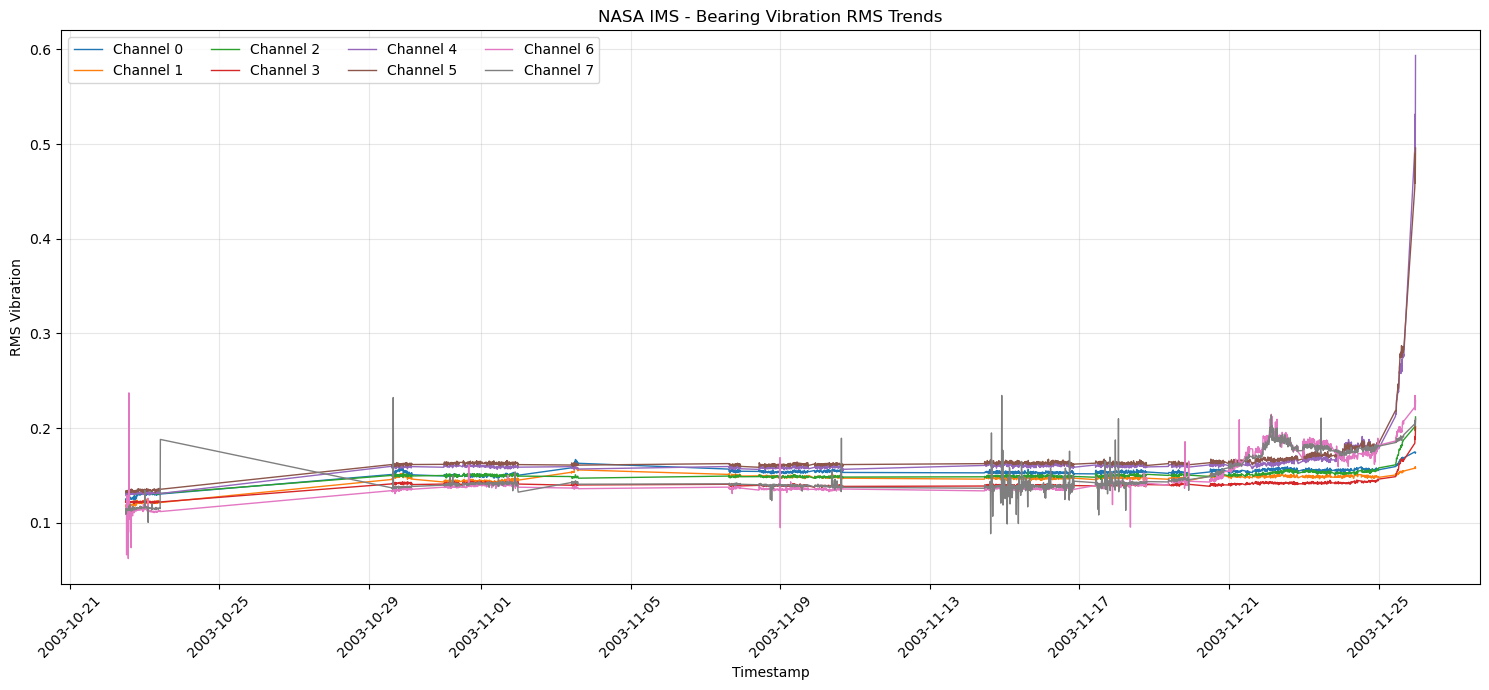

In [14]:
plt.figure(figsize=(15, 7))

for i in range(8):
    plt.plot(
        rms_df["Timestamp"],
        rms_df[f"RMS_CH_{i}"],
        label=f"Channel {i}",
        linewidth=1
    )

plt.title("NASA IMS - Bearing Vibration RMS Trends")
plt.xlabel("Timestamp")
plt.ylabel("RMS Vibration")
plt.legend(ncol=4)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 11 — Calculate the baseline Health Indicator
We'll use the first 20% of recordings as a provisional baseline. This is a starting assumption, not a confirmed healthy period.

In [17]:
# Sort recordings chronologically
rms_df = rms_df.sort_values("Timestamp").reset_index(drop=True)

# Identify RMS columns
rms_columns = [f"RMS_CH_{i}" for i in range(8)]

# Use first 20% as provisional baseline
baseline_size = int(len(rms_df) * 0.20)

# Calculate median baseline for each channel
baseline = rms_df.loc[:baseline_size - 1, rms_columns].median()

print("Baseline RMS values:")
display(baseline)

Baseline RMS values:


RMS_CH_0    0.149417
RMS_CH_1    0.143377
RMS_CH_2    0.149464
RMS_CH_3    0.141114
RMS_CH_4    0.158952
RMS_CH_5    0.161723
RMS_CH_6    0.135654
RMS_CH_7    0.138096
dtype: float64

In [21]:
# calculate health indicators

hi_df = rms_df.copy()

for col in rms_columns:
    hi_df[f"HI_{col}"] = (
        hi_df[col] / baseline[col]
    )

print("Health Indicator calculation completed!")

display(hi_df.head())

Health Indicator calculation completed!


,Timestamp,RMS_CH_0,RMS_CH_1,RMS_CH_2,RMS_CH_3,RMS_CH_4,RMS_CH_5,RMS_CH_6,RMS_CH_7,HI_RMS_CH_0,HI_RMS_CH_1,HI_RMS_CH_2,HI_RMS_CH_3,HI_RMS_CH_4,HI_RMS_CH_5,HI_RMS_CH_6,HI_RMS_CH_7
0,2003-10-22 12:06:24,0.124614,0.117493,0.130455,0.121642,0.128887,0.131821,0.109020,0.115267,0.834000,0.819468,0.872822,0.862012,0.810857,0.815104,0.803669,0.834689
1,2003-10-22 12:09:13,0.123811,0.116833,0.131490,0.122182,0.129562,0.132049,0.108900,0.109208,0.828628,0.814860,0.879744,0.865836,0.815104,0.816513,0.802777,0.790810
2,2003-10-22 12:14:13,0.125246,0.118384,0.131906,0.123572,0.131339,0.133300,0.110319,0.113696,0.838233,0.825684,0.882525,0.875690,0.826282,0.824251,0.813242,0.823310
3,2003-10-22 12:19:13,0.125197,0.119005,0.131614,0.122750,0.131083,0.133969,0.111037,0.114413,0.837906,0.830009,0.880575,0.869865,0.824671,0.828386,0.818535,0.828501
4,2003-10-22 12:24:13,0.125618,0.119688,0.130779,0.121866,0.131307,0.133281,0.110190,0.114258,0.840721,0.834779,0.874986,0.863598,0.826084,0.824129,0.812292,0.827377


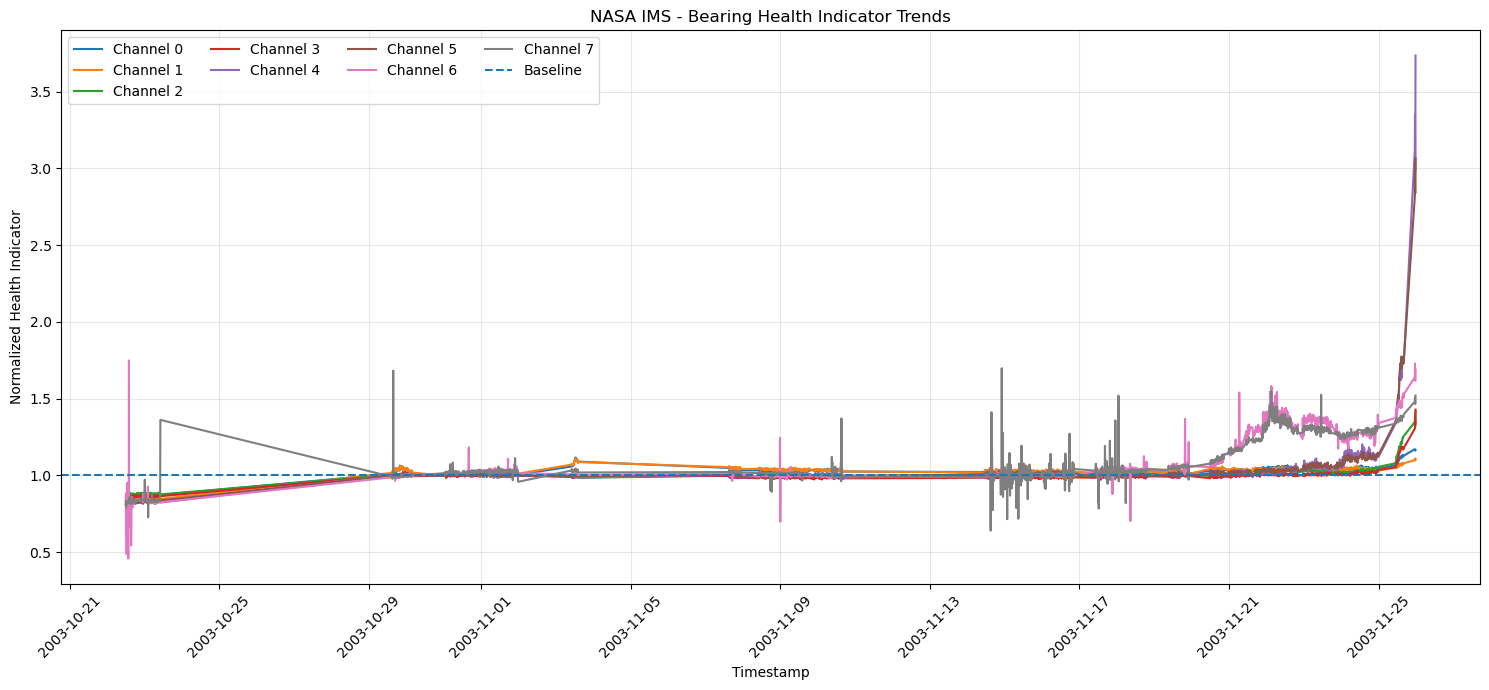

In [23]:
plt.figure(figsize=(15, 7))

for i in range(8):
    plt.plot(
        hi_df["Timestamp"],
        hi_df[f"HI_RMS_CH_{i}"],
        label=f"Channel {i}"
    )

plt.axhline(1, linestyle="--", label="Baseline")

plt.title("NASA IMS - Bearing Health Indicator Trends")
plt.xlabel("Timestamp")
plt.ylabel("Normalized Health Indicator")
plt.legend(ncol=4)
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 14 — Identify the most affected channels numerically
Let's calculate the final HI, maximum HI and percentage increase for every channel.

In [26]:
channel_summary = []

for i in range(8):

    col = f"HI_RMS_CH_{i}"

    baseline_value = 1.0
    final_value = hi_df[col].iloc[-1]
    maximum_value = hi_df[col].max()

    channel_summary.append({
        "Channel": f"CH_{i}",
        "Final_HI": final_value,
        "Maximum_HI": maximum_value,
        "Final_Increase_Percent": (final_value - 1) * 100
    })

channel_summary_df = pd.DataFrame(channel_summary)

channel_summary_df = channel_summary_df.sort_values(
    "Maximum_HI",
    ascending=False
)

display(channel_summary_df.round(3))

,Channel,Final_HI,Maximum_HI,Final_Increase_Percent
4,CH_4,3.735,3.735,273.453
5,CH_5,3.067,3.067,206.698
6,CH_6,1.689,1.749,68.942
7,CH_7,1.520,1.698,52.016
3,CH_3,1.429,1.429,42.861
2,CH_2,1.417,1.417,41.747
0,CH_0,1.166,1.171,16.574
1,CH_1,1.102,1.112,10.193


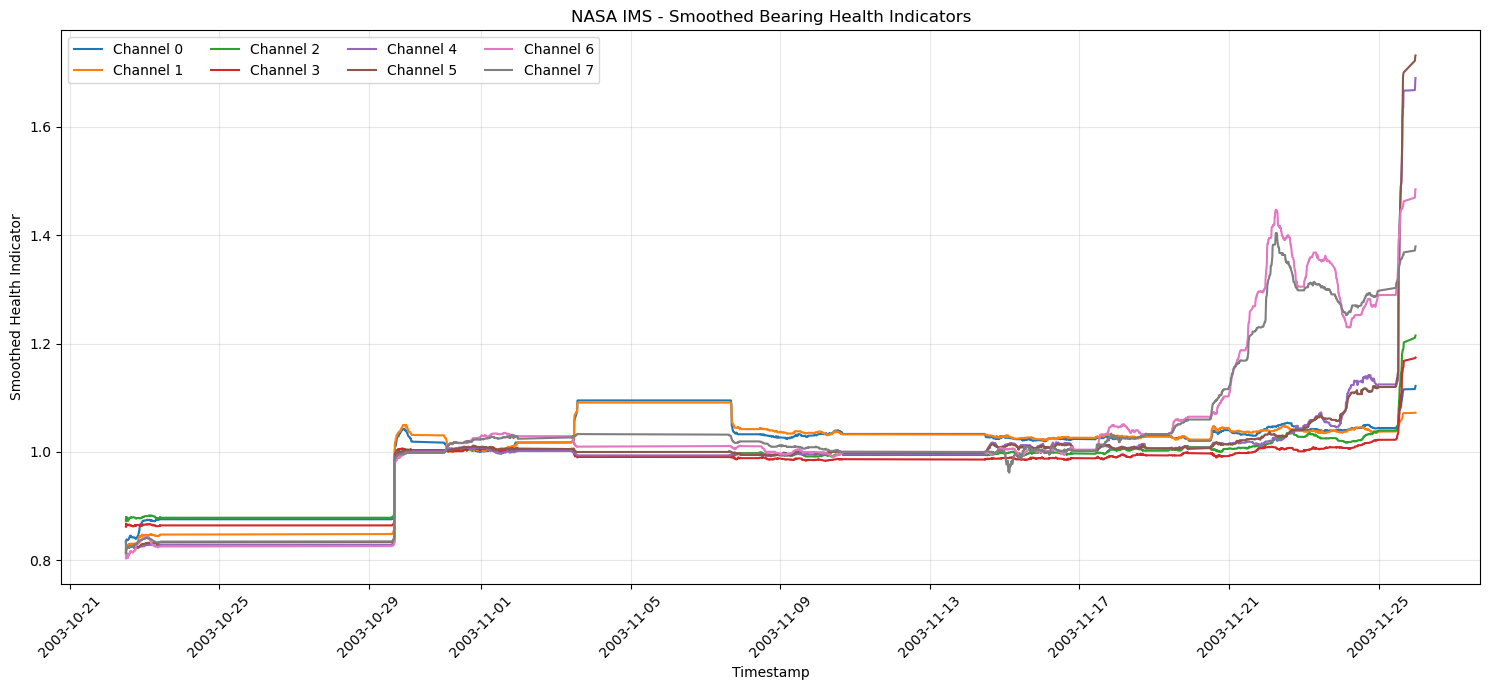

In [28]:
hi_smooth_df = hi_df.copy()

for i in range(8):

    col = f"HI_RMS_CH_{i}"

    hi_smooth_df[f"Smooth_{col}"] = (
        hi_smooth_df[col]
        .rolling(window=25, min_periods=1)
        .median()
    )

plt.figure(figsize=(15, 7))

for i in range(8):

    plt.plot(
        hi_smooth_df["Timestamp"],
        hi_smooth_df[f"Smooth_HI_RMS_CH_{i}"],
        label=f"Channel {i}"
    )

plt.title("NASA IMS - Smoothed Bearing Health Indicators")
plt.xlabel("Timestamp")
plt.ylabel("Smoothed Health Indicator")
plt.legend(ncol=4)
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#2. Next: Smooth the Health Indicator
Before building our RUL model, we need to distinguish sustained degradation from isolated vibration spikes

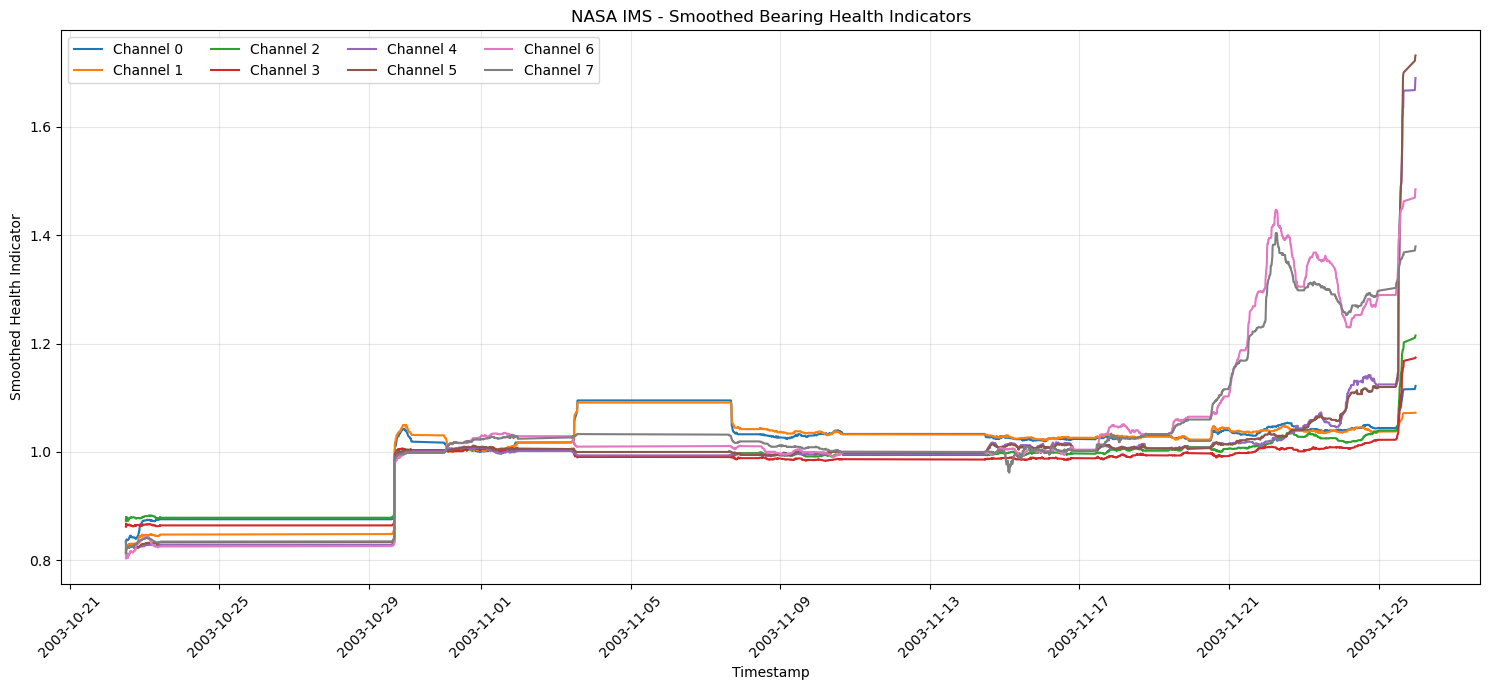

In [33]:
hi_smooth_df = hi_df.copy()

for i in range(8):
    col = f"HI_RMS_CH_{i}"

    hi_smooth_df[f"Smooth_{col}"] = (
        hi_smooth_df[col]
        .rolling(window=25, min_periods=1)
        .median()
    )

plt.figure(figsize=(15, 7))

for i in range(8):
    plt.plot(
        hi_smooth_df["Timestamp"],
        hi_smooth_df[f"Smooth_HI_RMS_CH_{i}"],
        label=f"Channel {i}"
    )

plt.title("NASA IMS - Smoothed Bearing Health Indicators")
plt.xlabel("Timestamp")
plt.ylabel("Smoothed Health Indicator")
plt.legend(ncol=4)
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Step 16 — Investigate timestamp intervals
The NASA IMS recordings are not necessarily collected at perfectly equal intervals. Let's calculate the time difference between consecutive files.

In [36]:
# Calculate time difference between consecutive recordings
hi_df["Time_Difference"] = (
    hi_df["Timestamp"].diff()
)

print("Most common recording intervals:")
display(
    hi_df["Time_Difference"]
    .value_counts()
    .head(10)
)

print("\nLargest time gaps:")

display(
    hi_df.nlargest(10, "Time_Difference")[
        ["Timestamp", "Time_Difference"]
    ]
)

Most common recording intervals:


Time_Difference
0 days 00:10:00    1962
0 days 00:05:00     145
0 days 00:06:02       1
0 days 01:41:47       1
0 days 00:01:50       1
0 days 13:34:28       1
0 days 00:03:28       1
0 days 03:01:16       1
0 days 00:03:44       1
0 days 02:15:18       1
Name: count, dtype: int64


Largest time gaps:


,Timestamp,Time_Difference
156,2003-10-29 14:39:46,6 days 04:25:33
540,2003-11-07 14:51:44,4 days 00:30:00
893,2003-11-14 11:02:17,3 days 18:36:19
512,2003-11-03 09:53:55,1 days 10:02:11
235,2003-10-31 00:09:46,0 days 20:30:00
1435,2003-11-19 09:06:09,0 days 13:53:39
1236,2003-11-17 10:18:56,0 days 13:50:10
1507,2003-11-20 11:50:35,0 days 13:34:28
588,2003-11-08 10:22:19,0 days 11:40:35
2119,2003-11-25 10:47:32,0 days 10:50:00


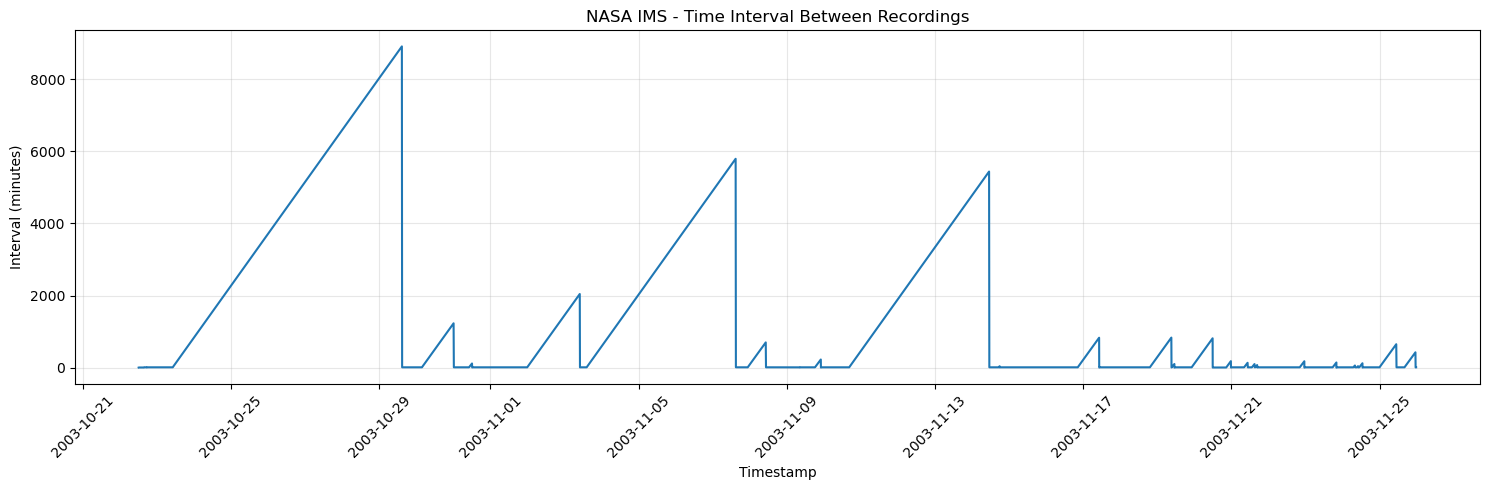

In [40]:
plt.figure(figsize=(15, 5))

plt.plot(
    hi_df["Timestamp"],
    hi_df["Time_Difference"].dt.total_seconds() / 60
)

plt.title("NASA IMS - Time Interval Between Recordings")
plt.xlabel("Timestamp")
plt.ylabel("Interval (minutes)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [44]:
# visualize recording gap
# Convert recording intervals into minutes
interval_minutes = (
    hi_df["Time_Difference"].dt.total_seconds() / 60
)

# Find gaps greater than 10 minutes
large_gaps = hi_df[
    interval_minutes > 10
][["Timestamp", "Time_Difference"]].copy()

print("Total large gaps:", len(large_gaps))

display(large_gaps.head(20))

Total large gaps: 24


,Timestamp,Time_Difference
156,2003-10-29 14:39:46,6 days 04:25:33
235,2003-10-31 00:09:46,0 days 20:30:00
296,2003-10-31 12:05:51,0 days 01:56:05
512,2003-11-03 09:53:55,1 days 10:02:11
540,2003-11-07 14:51:44,4 days 00:30:00
588,2003-11-08 10:22:19,0 days 11:40:35
781,2003-11-09 22:02:15,0 days 03:46:17
893,2003-11-14 11:02:17,3 days 18:36:19
931,2003-11-14 17:52:14,0 days 00:39:57
1236,2003-11-17 10:18:56,0 days 13:50:10


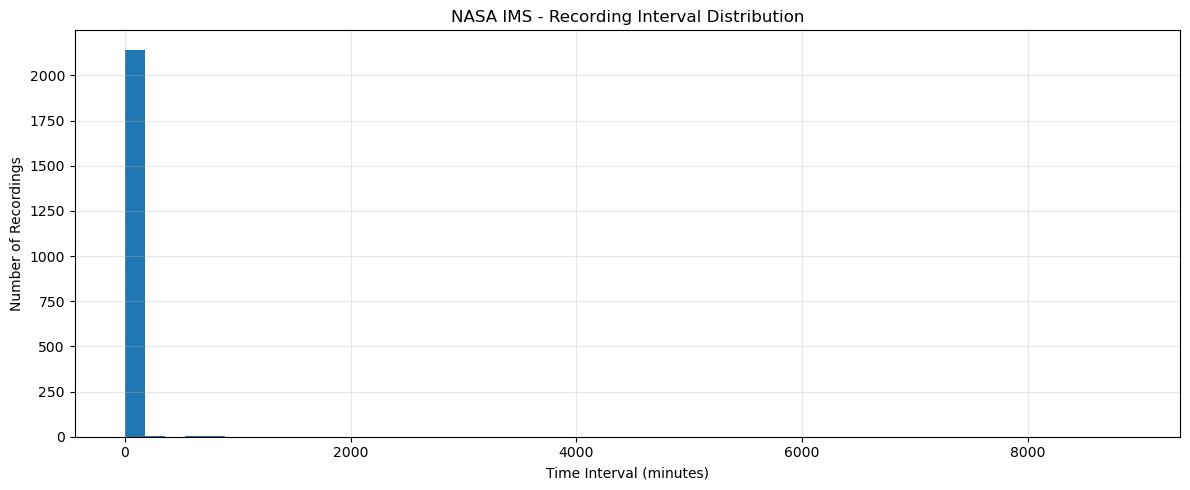

In [46]:
plt.figure(figsize=(12, 5))

plt.hist(
    interval_minutes.dropna(),
    bins=50
)

plt.title("NASA IMS - Recording Interval Distribution")
plt.xlabel("Time Interval (minutes)")
plt.ylabel("Number of Recordings")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

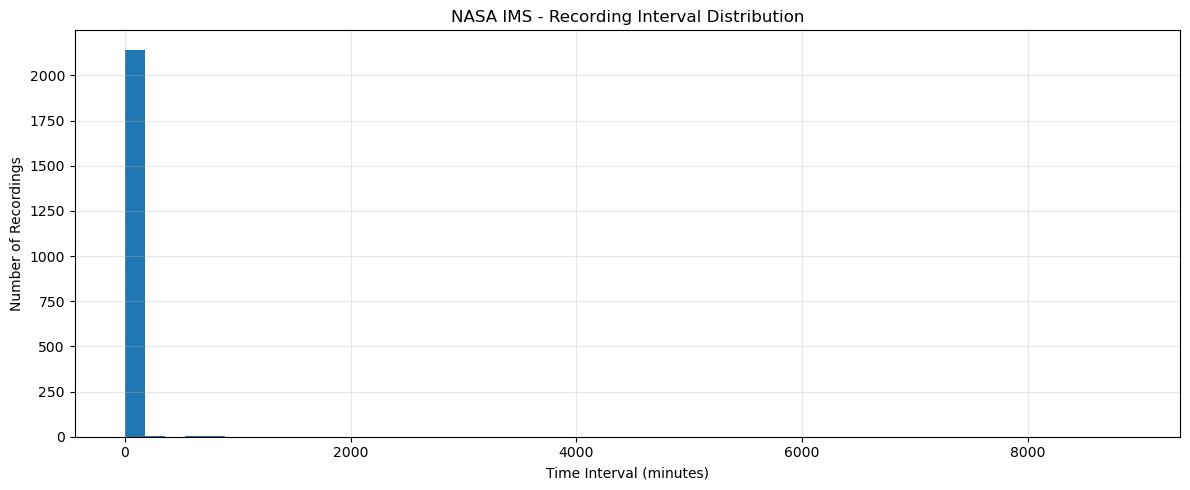

In [48]:
interval_minutes = hi_df["Time_Difference"].dt.total_seconds() / 60

plt.figure(figsize=(12, 5))

plt.hist(interval_minutes.dropna(), bins=50)

plt.title("NASA IMS - Recording Interval Distribution")
plt.xlabel("Time Interval (minutes)")
plt.ylabel("Number of Recordings")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
print("Median interval:", interval_minutes.median(), "minutes")
print("Mean interval:", interval_minutes.mean(), "minutes")
print("Minimum interval:", interval_minutes.min(), "minutes")
print("Maximum interval:", interval_minutes.max(), "minutes")

Median interval: 10.0 minutes
Mean interval: 23.041082753286933 minutes
Minimum interval: 0.21666666666666667 minutes
Maximum interval: 8905.55 minutes


Step 20 — Check whether recording gaps caused HI jumps
Run this cell. It compares the HI immediately before and after every recording gap greater than 10 minutes.

In [53]:
# Identify rows where the recording gap is greater than 10 minutes
gap_indices = hi_df.index[
    hi_df["Time_Difference"] > pd.Timedelta(minutes=10)
]

# Compare HI values before and after each gap
gap_analysis = []

for idx in gap_indices:
    for i in range(8):

        col = f"HI_RMS_CH_{i}"

        previous_hi = hi_df.loc[idx - 1, col]
        current_hi = hi_df.loc[idx, col]

        gap_analysis.append({
            "Timestamp": hi_df.loc[idx, "Timestamp"],
            "Gap_Minutes": (
                hi_df.loc[idx, "Time_Difference"].total_seconds() / 60
            ),
            "Channel": f"CH_{i}",
            "Previous_HI": previous_hi,
            "Current_HI": current_hi,
            "HI_Change": current_hi - previous_hi
        })

gap_analysis_df = pd.DataFrame(gap_analysis)

display(
    gap_analysis_df.sort_values(
        "HI_Change", ascending=False
    ).head(20).round(3)
)

,Timestamp,Gap_Minutes,Channel,Previous_HI,Current_HI,HI_Change
188,2003-11-25 23:13:21,425.817,CH_4,1.734,3.122,1.387
189,2003-11-25 23:13:21,425.817,CH_5,1.750,2.814,1.064
180,2003-11-25 10:47:32,650.000,CH_4,1.121,1.337,0.216
181,2003-11-25 10:47:32,650.000,CH_5,1.136,1.351,0.215
4,2003-10-29 14:39:46,8905.550,CH_4,0.824,1.005,0.181
1,2003-10-29 14:39:46,8905.550,CH_1,0.847,1.017,0.170
6,2003-10-29 14:39:46,8905.550,CH_6,0.825,0.988,0.163
5,2003-10-29 14:39:46,8905.550,CH_5,0.837,0.999,0.162
0,2003-10-29 14:39:46,8905.550,CH_0,0.873,1.011,0.138
3,2003-10-29 14:39:46,8905.550,CH_3,0.865,1.000,0.135


In [55]:
# Step 21 — Mark unusual recording gaps
# Create a copy of the Health Indicator dataset
hi_clean_df = hi_df.copy()

# Mark recording gaps greater than 10 minutes
hi_clean_df["Large_Gap"] = (
    hi_clean_df["Time_Difference"] > pd.Timedelta(minutes=10)
)

# Display gap information
print("Total recordings:", len(hi_clean_df))

print(
    "Recordings after large gaps:",
    hi_clean_df["Large_Gap"].sum()
)

print("\nGap distribution:")
print(hi_clean_df["Large_Gap"].value_counts())

Total recordings: 2156
Recordings after large gaps: 24

Gap distribution:
Large_Gap
False    2132
True       24
Name: count, dtype: int64


- Total recordings: 2,156
- Normal intervals (10 minutes or less): 2,132
- Large gaps (greater than 10 minutes): 24
- Percentage of recordings after large gaps: approximately 1.11%
We have successfully identified and marked the irregular recording intervals without deleting any useful data.

Step 22 — Combine the two vibration directions for each bearing
The NASA IMS dataset contains 8 channels representing 4 bearings, with 2 vibration directions per bearing.

Let's calculate one combined RMS-based Health Indicator for each bearing by averaging its two channel HIs.

In [59]:
# Create a copy of our cleaned HI dataset
bearing_hi_df = hi_clean_df.copy()

# Combine the two directions for each bearing
bearing_hi_df["Bearing_1_HI"] = (
    bearing_hi_df["HI_RMS_CH_0"] +
    bearing_hi_df["HI_RMS_CH_1"]
) / 2

bearing_hi_df["Bearing_2_HI"] = (
    bearing_hi_df["HI_RMS_CH_2"] +
    bearing_hi_df["HI_RMS_CH_3"]
) / 2

bearing_hi_df["Bearing_3_HI"] = (
    bearing_hi_df["HI_RMS_CH_4"] +
    bearing_hi_df["HI_RMS_CH_5"]
) / 2

bearing_hi_df["Bearing_4_HI"] = (
    bearing_hi_df["HI_RMS_CH_6"] +
    bearing_hi_df["HI_RMS_CH_7"]
) / 2

# Display the first five rows
display(
    bearing_hi_df[
        [
            "Timestamp",
            "Bearing_1_HI",
            "Bearing_2_HI",
            "Bearing_3_HI",
            "Bearing_4_HI"
        ]
    ].head().round(3)
)

,Timestamp,Bearing_1_HI,Bearing_2_HI,Bearing_3_HI,Bearing_4_HI
0,2003-10-22 12:06:24,0.827,0.867,0.813,0.819
1,2003-10-22 12:09:13,0.822,0.873,0.816,0.797
2,2003-10-22 12:14:13,0.832,0.879,0.825,0.818
3,2003-10-22 12:19:13,0.834,0.875,0.827,0.824
4,2003-10-22 12:24:13,0.838,0.869,0.825,0.820


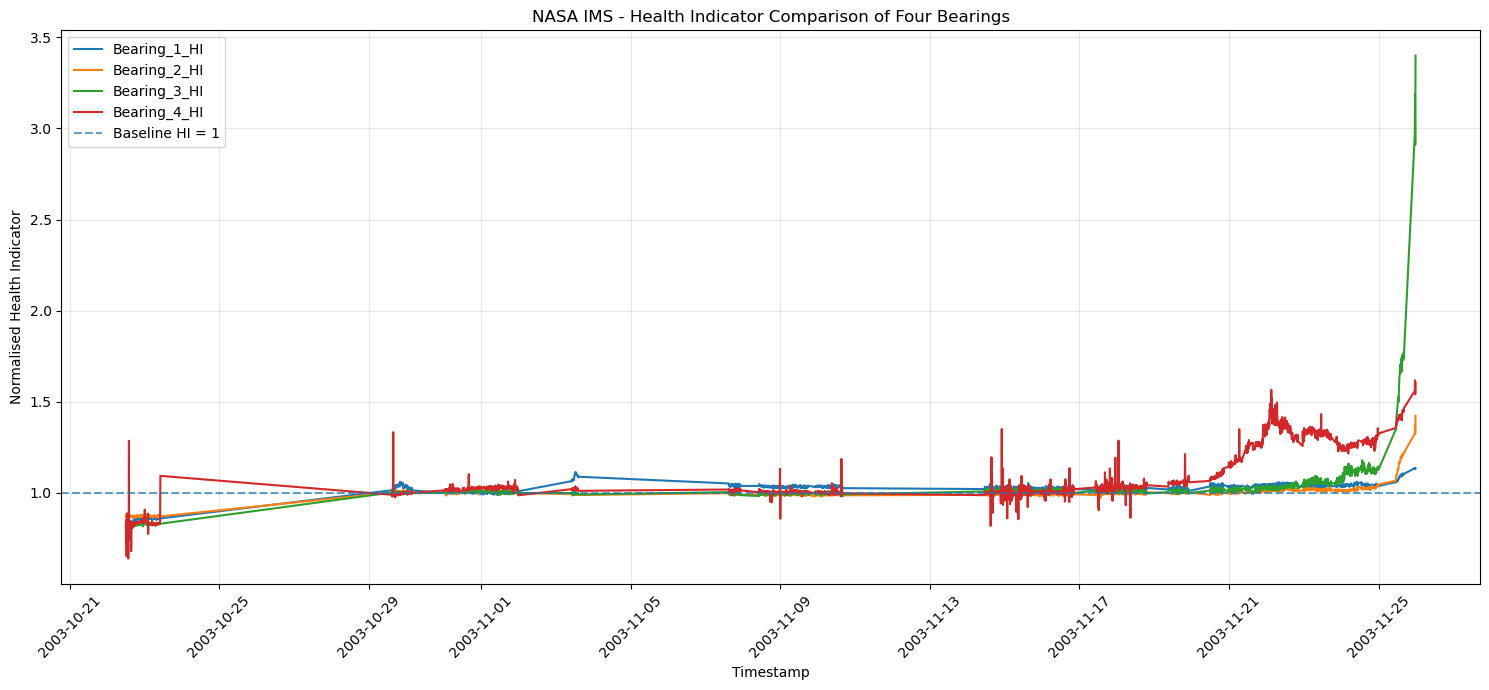

In [61]:
plt.figure(figsize=(15, 7))

bearing_columns = [
    "Bearing_1_HI",
    "Bearing_2_HI",
    "Bearing_3_HI",
    "Bearing_4_HI"
]

for col in bearing_columns:
    plt.plot(
        bearing_hi_df["Timestamp"],
        bearing_hi_df[col],
        label=col
    )

plt.axhline(
    y=1,
    linestyle="--",
    alpha=0.7,
    label="Baseline HI = 1"
)

plt.title("NASA IMS - Health Indicator Comparison of Four Bearings")
plt.xlabel("Timestamp")
plt.ylabel("Normalised Health Indicator")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 24 — Smooth the four bearing-level indicators
Before identifying degradation onset, let's reduce short-term fluctuations while preserving the original data.

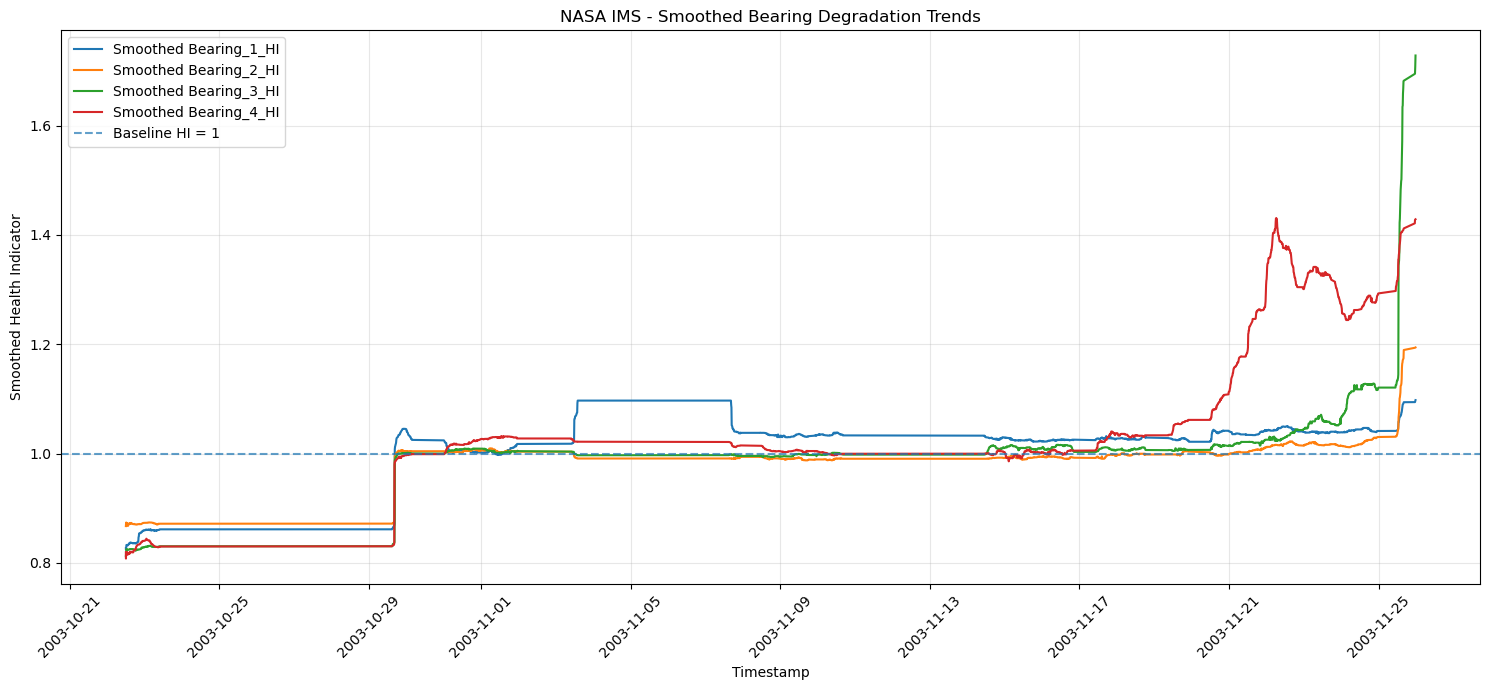

In [64]:
# Create a separate dataframe for smoothed indicators
bearing_smooth_df = bearing_hi_df.copy()

bearing_columns = [
    "Bearing_1_HI",
    "Bearing_2_HI",
    "Bearing_3_HI",
    "Bearing_4_HI"
]

# Apply a 25-recording rolling median
for col in bearing_columns:
    bearing_smooth_df[f"Smooth_{col}"] = (
        bearing_smooth_df[col]
        .rolling(window=25, min_periods=1)
        .median()
    )

# Plot smoothed degradation trends
plt.figure(figsize=(15, 7))

for col in bearing_columns:
    plt.plot(
        bearing_smooth_df["Timestamp"],
        bearing_smooth_df[f"Smooth_{col}"],
        label=f"Smoothed {col}"
    )

plt.axhline(y=1, linestyle="--", alpha=0.7, label="Baseline HI = 1")

plt.title("NASA IMS - Smoothed Bearing Degradation Trends")
plt.xlabel("Timestamp")
plt.ylabel("Smoothed Health Indicator")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 25 — Calculate degradation onset
For this first analysis, let's use:
- Baseline HI: 1.0
- Degradation threshold: 1.2 (20% above baseline)
- Persistence: 25 consecutive recordings above the threshold.
This is an exploratory rule, not a universally validated failure threshold.

In [67]:
# Define degradation detection settings
threshold = 1.2
persistence = 25

bearing_columns = [
    "Bearing_1_HI",
    "Bearing_2_HI",
    "Bearing_3_HI",
    "Bearing_4_HI"
]

onset_results = []

for col in bearing_columns:

    smooth_col = f"Smooth_{col}"

    # Identify recordings where smoothed HI exceeds threshold
    above_threshold = (
        bearing_smooth_df[smooth_col] > threshold
    )

    # Find the first sustained period of 25 consecutive recordings
    sustained = (
        above_threshold
        .rolling(window=persistence, min_periods=persistence)
        .sum()
        .eq(persistence)
    )

    if sustained.any():

        onset_index = sustained[sustained].index[0]

        onset_results.append({
            "Bearing": col.replace("_HI", ""),
            "Degradation_Onset": bearing_smooth_df.loc[
                onset_index - persistence + 1, "Timestamp"
            ],
            "Detection_Confirmed": bearing_smooth_df.loc[
                onset_index, "Timestamp"
            ],
            "HI_at_Onset": bearing_smooth_df.loc[
                onset_index - persistence + 1, smooth_col
            ]
        })

    else:

        onset_results.append({
            "Bearing": col.replace("_HI", ""),
            "Degradation_Onset": "Not detected",
            "Detection_Confirmed": "Not detected",
            "HI_at_Onset": None
        })

onset_df = pd.DataFrame(onset_results)

display(onset_df)

,Bearing,Degradation_Onset,Detection_Confirmed,HI_at_Onset
0,Bearing_1,Not detected,Not detected,NaN
1,Bearing_2,Not detected,Not detected,NaN
2,Bearing_3,2003-11-25 12:47:32,2003-11-25 23:39:56,1.344004
3,Bearing_4,2003-11-21 12:18:36,2003-11-21 18:46:56,1.219136


Step 25 — Results interpretation
Degradation detected in 2 bearings
Bearing	Degradation onset	Detection confirmed
Bearing 1	Not detected	Not detected
Bearing 2	Not detected	Not detected
Bearing 3	Nov 25, 12:47	Nov 25, 23:39
Bearing 4	Nov 21, 12:18	Nov 21, 18:46

1. What have we discovered?
Bearing 4 — Earlier degradation
- First sustained threshold crossing: November 21, 12:18.
- Detection confirmed: November 21, 18:46.
- HI at onset: 1.219.
Bearing 3 — Late-stage degradation
- First sustained threshold crossing: November 25, 12:47.
- Detection confirmed: November 25, 23:39.
- HI at onset: 1.344.
Bearing 1 and Bearing 2

They did not satisfy our rule of 25 consecutive recordings above 1.2.

This does not prove that they are healthy. It means our current detection rule did not identify sustained degradation in them.
2. An important limitation
Our rolling window uses 25 recordings, not 25 fixed time intervals. Because the dataset contains missing periods, the time between onset and confirmation is not necessarily constant.

Also, the 1.2 threshold is an exploratory choice. We'll validate it before using it in the final model.
Step 26 — Calculate the degradation severity
Let's quantify how much each bearing's HI increased from baseline to its final recording.

Run this cell:

In [70]:
severity_results = []

for col in bearing_columns:

    smooth_col = f"Smooth_{col}"

    initial_hi = bearing_smooth_df[smooth_col].iloc[0]
    final_hi = bearing_smooth_df[smooth_col].iloc[-1]
    maximum_hi = bearing_smooth_df[smooth_col].max()

    severity_results.append({
        "Bearing": col.replace("_HI", ""),
        "Initial_HI": initial_hi,
        "Final_HI": final_hi,
        "Maximum_HI": maximum_hi,
        "Total_Increase_Percent": (
            (final_hi - initial_hi) / initial_hi
        ) * 100
    })

severity_df = pd.DataFrame(severity_results)

display(
    severity_df.sort_values(
        "Final_HI", ascending=False
    ).round(3)
)

,Bearing,Initial_HI,Final_HI,Maximum_HI,Total_Increase_Percent
2,Bearing_3,0.813,1.728,1.728,112.584
3,Bearing_4,0.819,1.429,1.430,74.402
1,Bearing_2,0.867,1.194,1.194,37.674
0,Bearing_1,0.827,1.098,1.098,32.794


Step 26 — Results interpretation
Bearing comparison completed
Rank	Bearing	Initial HI	Final HI	Increase
1	Bearing 3	0.813	1.728	112.58%
2	Bearing 4	0.819	1.429	74.40%
3	Bearing 2	0.867	1.194	37.67%
4	Bearing 1	0.827	1.098	32.79%

Key findings
1. Bearing 3: Highest final HI and largest percentage increase.
2. Bearing 4: Second-highest increase, with earlier sustained degradation.
3. Bearing 2: Moderate increase.
4. Bearing 1: Lowest increase.
One clarification: Total_Increase_Percent is calculated relative to the first smoothed HI value, not the baseline HI of 1.0. These percentages describe changes in our engineered indicator, not percentages of physical damage.

tep 27 — Prepare the time-based RUL target
Before training a prediction model, we need to establish what our target actually represents.

For now, we'll calculate the time remaining until the last available recording. This is an experiment-end proxy, not yet a verified bearing-specific failure time.

In [74]:
# Create a separate modelling dataframe
nasa_model_df = bearing_smooth_df[
    [
        "Timestamp",
        "Smooth_Bearing_1_HI",
        "Smooth_Bearing_2_HI",
        "Smooth_Bearing_3_HI",
        "Smooth_Bearing_4_HI"
    ]
].copy()

# Calculate elapsed time from the first recording
start_time = nasa_model_df["Timestamp"].iloc[0]

nasa_model_df["Elapsed_Hours"] = (
    nasa_model_df["Timestamp"] - start_time
).dt.total_seconds() / 3600

# Last available recording in the experiment
end_time = nasa_model_df["Timestamp"].iloc[-1]

# Calculate remaining time until the last recording
nasa_model_df["Experiment_Remaining_Hours"] = (
    end_time - nasa_model_df["Timestamp"]
).dt.total_seconds() / 3600

print("Experiment start:", start_time)
print("Experiment end:", end_time)

print(
    "Total experiment duration (hours):",
    round(nasa_model_df["Elapsed_Hours"].iloc[-1], 2)
)

display(nasa_model_df.head())

Experiment start: 2003-10-22 12:06:24
Experiment end: 2003-11-25 23:39:56
Total experiment duration (hours): 827.56


,Timestamp,Smooth_Bearing_1_HI,Smooth_Bearing_2_HI,Smooth_Bearing_3_HI,Smooth_Bearing_4_HI,Elapsed_Hours,Experiment_Remaining_Hours
0,2003-10-22 12:06:24,0.826734,0.867417,0.812981,0.819179,0.000000,827.558889
1,2003-10-22 12:09:13,0.824239,0.870103,0.814395,0.807986,0.046944,827.511944
2,2003-10-22 12:14:13,0.826734,0.872790,0.815809,0.818276,0.130278,827.428611
3,2003-10-22 12:19:13,0.829346,0.874005,0.820538,0.818727,0.213611,827.345278
4,2003-10-22 12:24:13,0.831958,0.872790,0.825107,0.819179,0.296944,827.261944


# Step 29 — Create bearing-specific RUL targets
Let's add separate RUL columns for Bearing 3 and Bearing 4.

In [77]:
# Create a copy of the modelling dataset
nasa_rul_df = nasa_model_df.copy()

# Use the last available recording as the approximate failure endpoint
failure_time = nasa_rul_df["Timestamp"].iloc[-1]

# Calculate RUL for the two bearings with reported failures
nasa_rul_df["Bearing_3_RUL_Hours"] = (
    failure_time - nasa_rul_df["Timestamp"]
).dt.total_seconds() / 3600

nasa_rul_df["Bearing_4_RUL_Hours"] = (
    failure_time - nasa_rul_df["Timestamp"]
).dt.total_seconds() / 3600

# Display selected columns
display(
    nasa_rul_df[
        [
            "Timestamp",
            "Smooth_Bearing_3_HI",
            "Bearing_3_RUL_Hours",
            "Smooth_Bearing_4_HI",
            "Bearing_4_RUL_Hours"
        ]
    ].head().round(3)
)

print("\nFinal RUL values:")
display(nasa_rul_df[
    ["Bearing_3_RUL_Hours", "Bearing_4_RUL_Hours"]
].tail())

,Timestamp,Smooth_Bearing_3_HI,Bearing_3_RUL_Hours,Smooth_Bearing_4_HI,Bearing_4_RUL_Hours
0,2003-10-22 12:06:24,0.813,827.559,0.819,827.559
1,2003-10-22 12:09:13,0.814,827.512,0.808,827.512
2,2003-10-22 12:14:13,0.816,827.429,0.818,827.429
3,2003-10-22 12:19:13,0.821,827.345,0.819,827.345
4,2003-10-22 12:24:13,0.825,827.262,0.819,827.262



Final RUL values:


,Bearing_3_RUL_Hours,Bearing_4_RUL_Hours
2151,7.540000,7.540000
2152,0.443056,0.443056
2153,0.333333,0.333333
2154,0.166667,0.166667
2155,0.000000,0.000000


#Step 30 — Clean up the modelling dataset
Let's remove the two duplicate RUL columns and retain the common target.

In [80]:
# Create the final exploratory RUL dataset
nasa_rul_df = nasa_model_df[
    [
        "Timestamp",
        "Elapsed_Hours",
        "Experiment_Remaining_Hours",
        "Smooth_Bearing_3_HI",
        "Smooth_Bearing_4_HI"
    ]
].copy()

# Rename the common target for clarity
nasa_rul_df.rename(
    columns={
        "Experiment_Remaining_Hours": "RUL_Proxy_Hours"
    },
    inplace=True
)

print("Dataset shape:", nasa_rul_df.shape)

print("\nMissing values:")
print(nasa_rul_df.isnull().sum())

print("\nDataset preview:")
display(nasa_rul_df.head())

Dataset shape: (2156, 5)

Missing values:
Timestamp              0
Elapsed_Hours          0
RUL_Proxy_Hours        0
Smooth_Bearing_3_HI    0
Smooth_Bearing_4_HI    0
dtype: int64

Dataset preview:


,Timestamp,Elapsed_Hours,RUL_Proxy_Hours,Smooth_Bearing_3_HI,Smooth_Bearing_4_HI
0,2003-10-22 12:06:24,0.000000,827.558889,0.812981,0.819179
1,2003-10-22 12:09:13,0.046944,827.511944,0.814395,0.807986
2,2003-10-22 12:14:13,0.130278,827.428611,0.815809,0.818276
3,2003-10-22 12:19:13,0.213611,827.345278,0.820538,0.818727
4,2003-10-22 12:24:13,0.296944,827.261944,0.825107,0.819179


# Step 30 completed
Dataset validation
Check	Result
Total recordings	2,156
Total columns	5
Missing values	0
Bearing indicators	2
RUL target	1 common experiment-end proxy

We have retained:
- Smooth_Bearing_3_HI
- Smooth_Bearing_4_HI
- Elapsed_Hours
- RUL_Proxy_Hours

# Step 31 — Analyse the relationship between HI and RUL
Before training a regression model, let's investigate whether increasing vibration indicators are associated with decreasing remaining experiment time.

Correlation Matrix:


,Smooth_Bearing_3_HI,Smooth_Bearing_4_HI,RUL_Proxy_Hours
Smooth_Bearing_3_HI,1.000,0.680,-0.631
Smooth_Bearing_4_HI,0.680,1.000,-0.765
RUL_Proxy_Hours,-0.631,-0.765,1.000


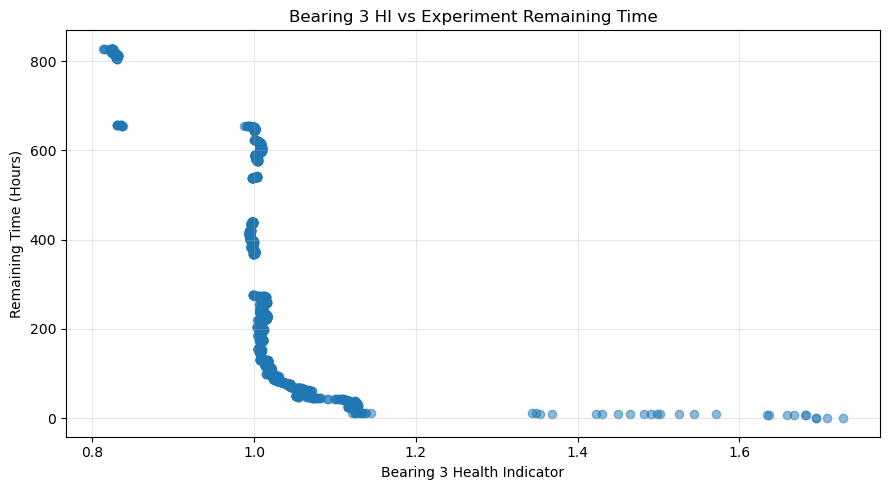

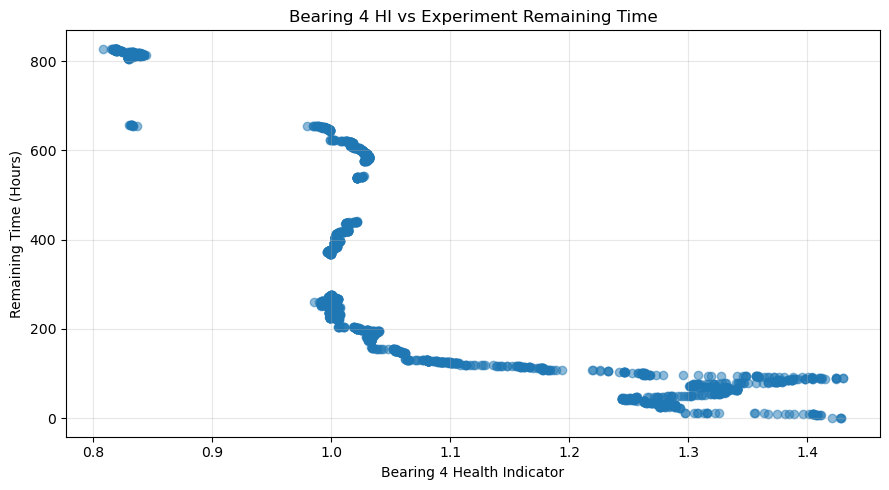

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between bearing HIs and RUL proxy
correlation_df = nasa_rul_df[
    [
        "Smooth_Bearing_3_HI",
        "Smooth_Bearing_4_HI",
        "RUL_Proxy_Hours"
    ]
].corr()

print("Correlation Matrix:")
display(correlation_df.round(3))

# Plot Bearing 3 HI against RUL proxy
plt.figure(figsize=(9, 5))

plt.scatter(
    nasa_rul_df["Smooth_Bearing_3_HI"],
    nasa_rul_df["RUL_Proxy_Hours"],
    alpha=0.5
)

plt.title("Bearing 3 HI vs Experiment Remaining Time")
plt.xlabel("Bearing 3 Health Indicator")
plt.ylabel("Remaining Time (Hours)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot Bearing 4 HI against RUL proxy
plt.figure(figsize=(9, 5))

plt.scatter(
    nasa_rul_df["Smooth_Bearing_4_HI"],
    nasa_rul_df["RUL_Proxy_Hours"],
    alpha=0.5
)

plt.title("Bearing 4 HI vs Experiment Remaining Time")
plt.xlabel("Bearing 4 Health Indicator")
plt.ylabel("Remaining Time (Hours)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 32 — Calculate Pearson, Spearman and R²

In [89]:
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
import pandas as pd

features = [
    "Smooth_Bearing_3_HI",
    "Smooth_Bearing_4_HI"
]

target = nasa_rul_df["RUL_Proxy_Hours"]

results = []

for feature in features:

    X = nasa_rul_df[[feature]]

    # Pearson correlation
    pearson_corr, pearson_p = pearsonr(
        nasa_rul_df[feature], target
    )

    # Spearman correlation
    spearman_corr, spearman_p = spearmanr(
        nasa_rul_df[feature], target
    )

    # Simple linear regression for descriptive R-squared
    model = LinearRegression()
    model.fit(X, target)

    r2 = model.score(X, target)

    results.append({
        "Bearing": feature.replace("Smooth_", "").replace("_HI", ""),
        "Pearson": pearson_corr,
        "Spearman": spearman_corr,
        "R2": r2,
        "Pearson_p_value": pearson_p,
        "Spearman_p_value": spearman_p
    })

correlation_results = pd.DataFrame(results)

display(correlation_results.round(4))

,Bearing,Pearson,Spearman,R2,Pearson_p_value,Spearman_p_value
0,Bearing_3,-0.6308,-0.8632,0.3979,0.0,0.0
1,Bearing_4,-0.7646,-0.7981,0.5847,0.0,0.0


In [91]:
# Prepare the modelling dataset

model_df = nasa_rul_df[
    [
        "Timestamp",
        "Smooth_Bearing_3_HI",
        "Smooth_Bearing_4_HI",
        "RUL_Proxy_Hours"
    ]
].copy()

print("Dataset shape:", model_df.shape)
print("\nMissing values:")
print(model_df.isnull().sum())

display(model_df.head())

Dataset shape: (2156, 4)

Missing values:
Timestamp              0
Smooth_Bearing_3_HI    0
Smooth_Bearing_4_HI    0
RUL_Proxy_Hours        0
dtype: int64


,Timestamp,Smooth_Bearing_3_HI,Smooth_Bearing_4_HI,RUL_Proxy_Hours
0,2003-10-22 12:06:24,0.812981,0.819179,827.558889
1,2003-10-22 12:09:13,0.814395,0.807986,827.511944
2,2003-10-22 12:14:13,0.815809,0.818276,827.428611
3,2003-10-22 12:19:13,0.820538,0.818727,827.345278
4,2003-10-22 12:24:13,0.825107,0.819179,827.261944


Perfect. Your modelling dataset is ready.
2156 rows · 4 columns · No missing values
We have:
- Input features: Smooth_Bearing_3_HI, Smooth_Bearing_4_HI
- Target: RUL_Proxy_Hours
- Timestamp: Used to preserve chronological order, not as a model input.

# Step 1: Split the data chronologically
We'll use the first 80% for training and the last 20% for testing.

This is better than a random split because the model should be tested on later observations, simulating future prediction.

In [95]:
# Sort data by timestamp
model_df = model_df.sort_values("Timestamp").reset_index(drop=True)

# Define input features and target
X = model_df[
    ["Smooth_Bearing_3_HI", "Smooth_Bearing_4_HI"]
]

y = model_df["RUL_Proxy_Hours"]

# Chronological 80:20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(model_df["Timestamp"].iloc[0], "to",
      model_df["Timestamp"].iloc[split_index - 1])

print("\nTesting period:")
print(model_df["Timestamp"].iloc[split_index], "to",
      model_df["Timestamp"].iloc[-1])

Training samples: 1724
Testing samples: 432

Training period:
2003-10-22 12:06:24 to 2003-11-21 22:16:56

Testing period:
2003-11-21 22:26:56 to 2003-11-25 23:39:56


# Step 2: Train the Linear Regression model

In [98]:
# Import required libraries
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict RUL on test data
y_pred = lr_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION - MODEL PERFORMANCE")
print("--------------------------------------")
print(f"MAE  : {mae:.4f} hours")
print(f"RMSE : {rmse:.4f} hours")
print(f"R²   : {r2:.4f}")

LINEAR REGRESSION - MODEL PERFORMANCE
--------------------------------------
MAE  : 206.3243 hours
RMSE : 267.3274 hours
R²   : -109.8973


In [100]:
# Compare model predictions with a simple baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Baseline: always predict the average training RUL
baseline_pred = np.full(len(y_test), y_train.mean())

# Performance comparison
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred)
    ]
})

display(comparison.round(4))

# Compare actual and predicted RUL ranges
print("\nActual test RUL range:")
print(y_test.min(), "to", y_test.max())

print("\nPredicted test RUL range:")
print(y_pred.min(), "to", y_pred.max())

# Compare training and testing feature ranges
print("\nTraining feature ranges:")
display(X_train.agg(["min", "max"]).round(4))

print("\nTesting feature ranges:")
display(X_test.agg(["min", "max"]).round(4))

,Model,MAE,RMSE,R2
0,Mean Baseline,326.3565,327.3423,-165.2794
1,Linear Regression,206.3243,267.3274,-109.8973



Actual test RUL range:
0.0 to 97.21666666666667

Predicted test RUL range:
-1115.6680968556484 to 19.00771791135321

Training feature ranges:


,Smooth_Bearing_3_HI,Smooth_Bearing_4_HI
min,0.8130,0.808
max,1.0227,1.264



Testing feature ranges:


,Smooth_Bearing_3_HI,Smooth_Bearing_4_HI
min,1.0230,1.2443
max,1.7283,1.4303


.# Why Linear Regression failed
Linear Regression learned a relationship from the earlier observations and then extrapolated it into a new degradation range. Its predictions became unrealistic.
Current model is not suitable for RUL prediction
This does not mean Linear Regression is always unsuitable. It means this particular feature set and chronological split are challenging for this model.

TRAINING RUL
Minimum: 97.38333333333334
Maximum: 827.5588888888889
Mean: 383.1336715326115

TESTING RUL
Minimum: 0.0
Maximum: 97.21666666666667
Mean: 56.77715856481481


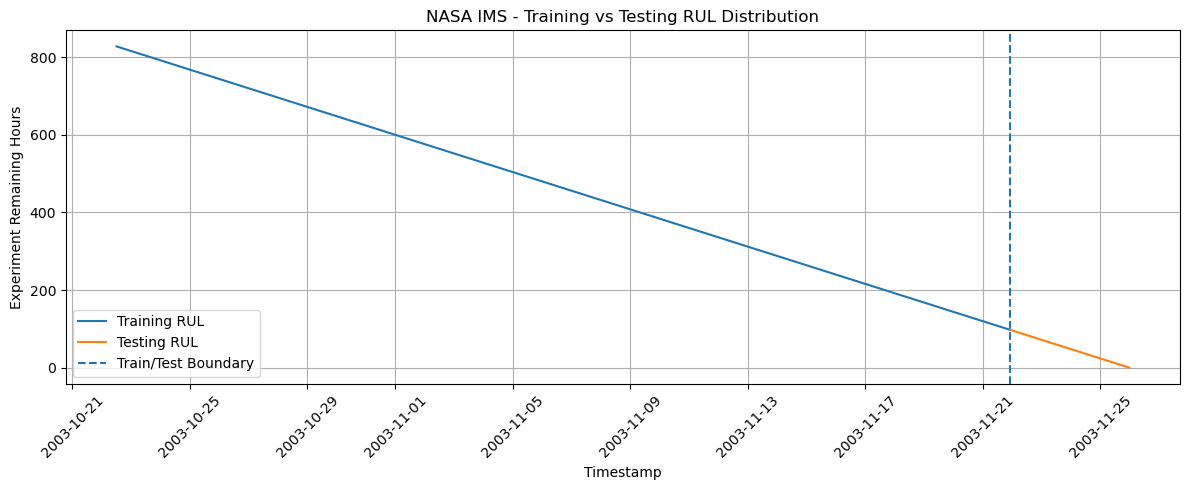

In [103]:
# . Next: Inspect the actual RUL distribution
# Compare training and testing RUL distributions

print("TRAINING RUL")
print("Minimum:", y_train.min())
print("Maximum:", y_train.max())
print("Mean:", y_train.mean())

print("\nTESTING RUL")
print("Minimum:", y_test.min())
print("Maximum:", y_test.max())
print("Mean:", y_test.mean())

# Plot actual RUL over time
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    model_df["Timestamp"].iloc[:split_index],
    y_train,
    label="Training RUL"
)

plt.plot(
    model_df["Timestamp"].iloc[split_index:],
    y_test,
    label="Testing RUL"
)

plt.axvline(
    model_df["Timestamp"].iloc[split_index],
    linestyle="--",
    label="Train/Test Boundary"
)

plt.xlabel("Timestamp")
plt.ylabel("Experiment Remaining Hours")
plt.title("NASA IMS - Training vs Testing RUL Distribution")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Let's compare the nonlinear models
We can still test Random Forest and Gradient Boosting as experiments, but we should not expect them to solve this extrapolation problem automatically.

In [106]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define models
models = {
    "Linear Regression": lr_model,

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

results = []

for name, model in models.items():

    # Train nonlinear models
    if name != "Linear Regression":
        model.fit(X_train, y_train)

    # Predict test data
    predictions = model.predict(X_test)

    # Evaluate
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
        "Minimum_Prediction": predictions.min(),
        "Maximum_Prediction": predictions.max()
    })

model_comparison = pd.DataFrame(results)

display(model_comparison.round(4))

,Model,MAE,RMSE,R2,Minimum_Prediction,Maximum_Prediction
0,Linear Regression,206.3243,267.3274,-109.8973,-1115.6681,19.0077
1,Random Forest,46.3201,52.8209,-3.3296,103.0942,103.1262
2,Gradient Boosting,69.0079,73.5290,-7.3898,125.7851,125.7851


# 1. Model comparison
Metric	Linear Regression	Random Forest	Gradient Boosting
MAE (hours)	206.32	46.32	69.01
RMSE (hours)	267.33	52.82	73.53
R²	-109.90	-3.33	-7.39

Best model: Random Forest
What this means
- Random Forest reduced MAE from 206.32 to 46.32 hours.
- Its RMSE is also the lowest.
- Gradient Boosting performed better than Linear Regression but worse than Random Forest.
- However, Random Forest still has a negative R² (-3.33). It is not yet a reliable predictive model.
- Its predictions range from -3.33 to 103.13 hours, including some physically impossible negative values.
The improvement is promising, but we must not call this a successful RUL predictor yet.

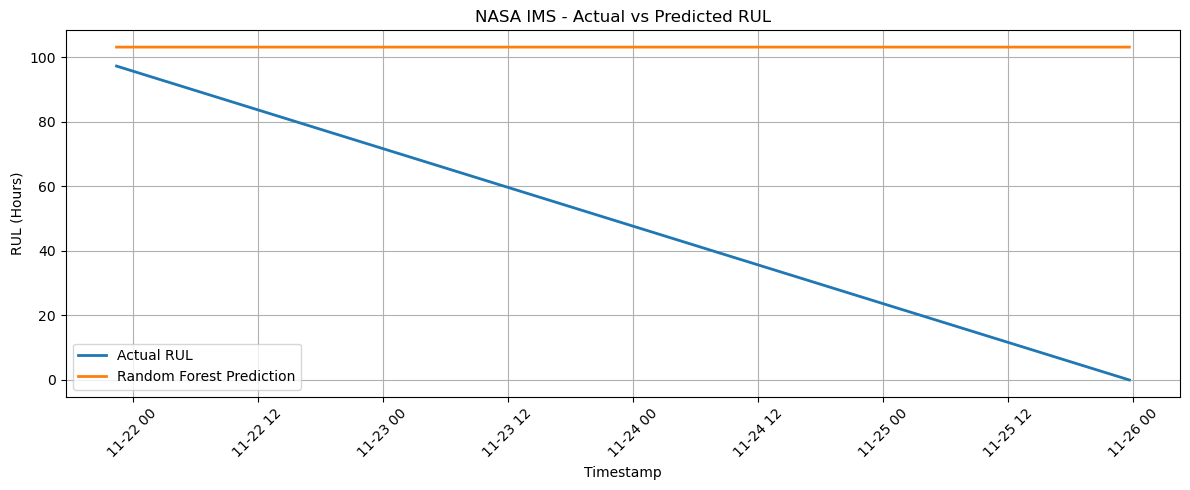

In [109]:
import matplotlib.pyplot as plt

rf_model = models["Random Forest"]
rf_predictions = rf_model.predict(X_test)

plt.figure(figsize=(12, 5))

plt.plot(
    model_df["Timestamp"].iloc[split_index:],
    y_test,
    label="Actual RUL",
    linewidth=2
)

plt.plot(
    model_df["Timestamp"].iloc[split_index:],
    rf_predictions,
    label="Random Forest Prediction",
    linewidth=2
)

plt.xlabel("Timestamp")
plt.ylabel("RUL (Hours)")
plt.title("NASA IMS - Actual vs Predicted RUL")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [111]:
# Examine Random Forest prediction variation

print("Random Forest Prediction Statistics")
print("------------------------------------")

print("Minimum:", rf_predictions.min())
print("Maximum:", rf_predictions.max())
print("Mean:", rf_predictions.mean())
print("Standard Deviation:", rf_predictions.std())
print("Number of unique predictions:", len(np.unique(rf_predictions)))

print("\nActual RUL Statistics")
print("---------------------")

print("Minimum:", y_test.min())
print("Maximum:", y_test.max())
print("Mean:", y_test.mean())
print("Standard Deviation:", y_test.std())

Random Forest Prediction Statistics
------------------------------------
Minimum: 103.09423512824196
Maximum: 103.12624901713087
Mean: 103.09727348343743
Standard Deviation: 0.00938285475423797
Number of unique predictions: 2

Actual RUL Statistics
---------------------
Minimum: 0.0
Maximum: 97.21666666666667
Mean: 56.77715856481481
Standard Deviation: 25.414769419411606


I recommend a different approach: # time-aware degradation modelling.

Instead of asking a tree model to extrapolate RUL from two health indicators, we can investigate whether the degradation trend itself can estimate remaining experiment time.

First, let's inspect the degradation trend of Bearing 3 and Bearing 4 during the test period.

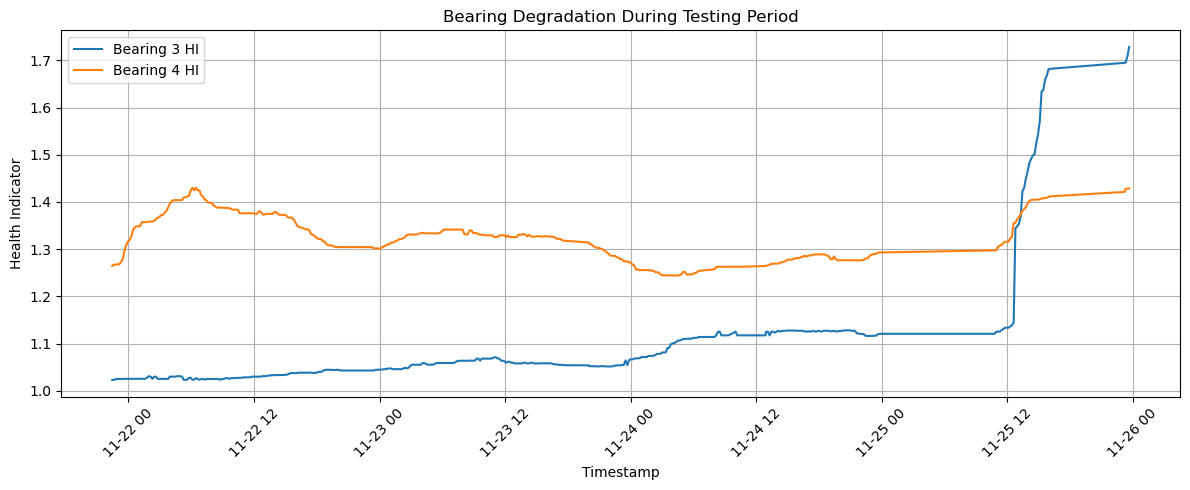

In [114]:
# Plot health indicators during the test period

plt.figure(figsize=(12, 5))

plt.plot(
    model_df["Timestamp"].iloc[split_index:],
    X_test["Smooth_Bearing_3_HI"],
    label="Bearing 3 HI"
)

plt.plot(
    model_df["Timestamp"].iloc[split_index:],
    X_test["Smooth_Bearing_4_HI"],
    label="Bearing 4 HI"
)

plt.xlabel("Timestamp")
plt.ylabel("Health Indicator")
plt.title("Bearing Degradation During Testing Period")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [116]:
# Step 1: Calculate degradation rate
# Calculate degradation rate for each bearing

degradation_df = model_df.copy()

degradation_df["Elapsed_Hours"] = (
    degradation_df["Timestamp"] - degradation_df["Timestamp"].iloc[0]
).dt.total_seconds() / 3600

degradation_df["Bearing_3_Rate"] = (
    degradation_df["Smooth_Bearing_3_HI"].diff()
    / degradation_df["Elapsed_Hours"].diff()
)

degradation_df["Bearing_4_Rate"] = (
    degradation_df["Smooth_Bearing_4_HI"].diff()
    / degradation_df["Elapsed_Hours"].diff()
)

print("Degradation Rate Summary")
display(
    degradation_df[
        ["Bearing_3_Rate", "Bearing_4_Rate"]
    ].describe().round(6)
)

Degradation Rate Summary


,Bearing_3_Rate,Bearing_4_Rate
count,2155.000000,2155.000000
mean,0.002404,0.001428
std,0.036870,0.027024
min,-0.445429,-0.708983
25%,-0.000017,0.000000
50%,0.000000,0.000000
75%,0.000957,0.002013
max,1.194655,0.860689


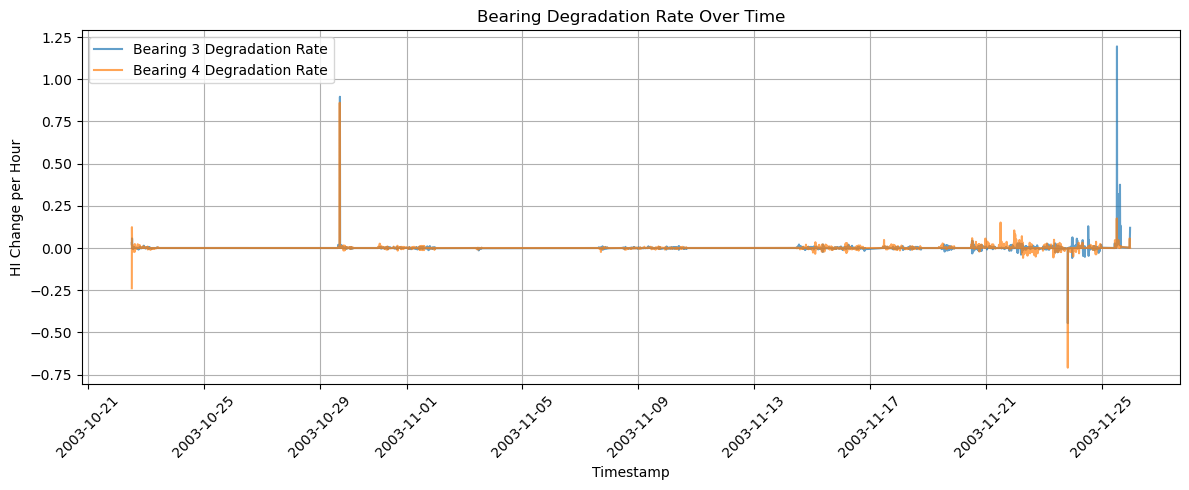

In [118]:
plt.figure(figsize=(12, 5))

plt.plot(
    degradation_df["Timestamp"],
    degradation_df["Bearing_3_Rate"],
    label="Bearing 3 Degradation Rate",
    alpha=0.7
)

plt.plot(
    degradation_df["Timestamp"],
    degradation_df["Bearing_4_Rate"],
    label="Bearing 4 Degradation Rate",
    alpha=0.7
)

plt.xlabel("Timestamp")
plt.ylabel("HI Change per Hour")
plt.title("Bearing Degradation Rate Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

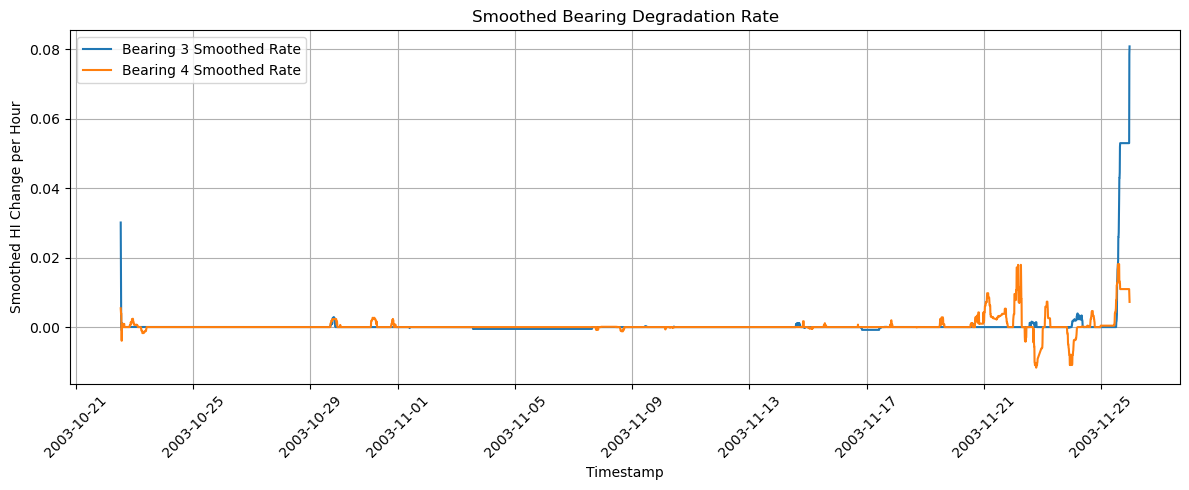

In [120]:
# Smooth degradation rates using rolling median

degradation_df["Bearing_3_Rate_Smooth"] = (
    degradation_df["Bearing_3_Rate"]
    .rolling(window=25, min_periods=5)
    .median()
)

degradation_df["Bearing_4_Rate_Smooth"] = (
    degradation_df["Bearing_4_Rate"]
    .rolling(window=25, min_periods=5)
    .median()
)

# Plot smoothed degradation rates

plt.figure(figsize=(12, 5))

plt.plot(
    degradation_df["Timestamp"],
    degradation_df["Bearing_3_Rate_Smooth"],
    label="Bearing 3 Smoothed Rate"
)

plt.plot(
    degradation_df["Timestamp"],
    degradation_df["Bearing_4_Rate_Smooth"],
    label="Bearing 4 Smoothed Rate"
)

plt.xlabel("Timestamp")
plt.ylabel("Smoothed HI Change per Hour")
plt.title("Smoothed Bearing Degradation Rate")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [122]:
# Estimate recent degradation rate

recent_data = degradation_df.tail(100).copy()

# Calculate rate using linear regression against elapsed time
from sklearn.linear_model import LinearRegression

def calculate_recent_rate(data, feature):
    X_time = data[["Elapsed_Hours"]]
    y_hi = data[feature]

    model = LinearRegression()
    model.fit(X_time, y_hi)

    return model.coef_[0]

rate_b3 = calculate_recent_rate(
    recent_data,
    "Smooth_Bearing_3_HI"
)

rate_b4 = calculate_recent_rate(
    recent_data,
    "Smooth_Bearing_4_HI"
)

print("Recent Degradation Rates")
print("------------------------")
print(f"Bearing 3: {rate_b3:.6f} HI units/hour")
print(f"Bearing 4: {rate_b4:.6f} HI units/hour")

Recent Degradation Rates
------------------------
Bearing 3: 0.015135 HI units/hour
Bearing 4: 0.004638 HI units/hour


In [124]:
# Current HI values
current_b3 = degradation_df["Smooth_Bearing_3_HI"].iloc[-1]
current_b4 = degradation_df["Smooth_Bearing_4_HI"].iloc[-1]

# Provisional threshold
failure_threshold = 1.2

# Estimate time to threshold
def estimate_time_to_threshold(current_hi, rate, threshold):
    if rate <= 0:
        return np.nan

    remaining = threshold - current_hi

    if remaining <= 0:
        return 0.0

    return remaining / rate

time_b3 = estimate_time_to_threshold(
    current_b3, rate_b3, failure_threshold
)

time_b4 = estimate_time_to_threshold(
    current_b4, rate_b4, failure_threshold
)

print("Estimated Time to HI Threshold")
print("--------------------------------")
print(f"Bearing 3: {time_b3:.2f} hours")
print(f"Bearing 4: {time_b4:.2f} hours")

Estimated Time to HI Threshold
--------------------------------
Bearing 3: 0.00 hours
Bearing 4: 0.00 hours


In [126]:
# Find first threshold crossing

threshold = 1.2

for bearing in ["Smooth_Bearing_3_HI", "Smooth_Bearing_4_HI"]:

    crossed = degradation_df[bearing] >= threshold

    if crossed.any():
        first_index = crossed[crossed].index[0]

        print(f"\n{bearing}")
        print("First crossing:", degradation_df.loc[first_index, "Timestamp"])
        print("HI at crossing:", round(degradation_df.loc[first_index, bearing], 4))
        print("Final HI:", round(degradation_df[bearing].iloc[-1], 4))
    else:
        print(f"\n{bearing}: Threshold not crossed")


Smooth_Bearing_3_HI
First crossing: 2003-11-25 12:47:32
HI at crossing: 1.344
Final HI: 1.7283

Smooth_Bearing_4_HI
First crossing: 2003-11-21 12:18:36
HI at crossing: 1.2191
Final HI: 1.4287


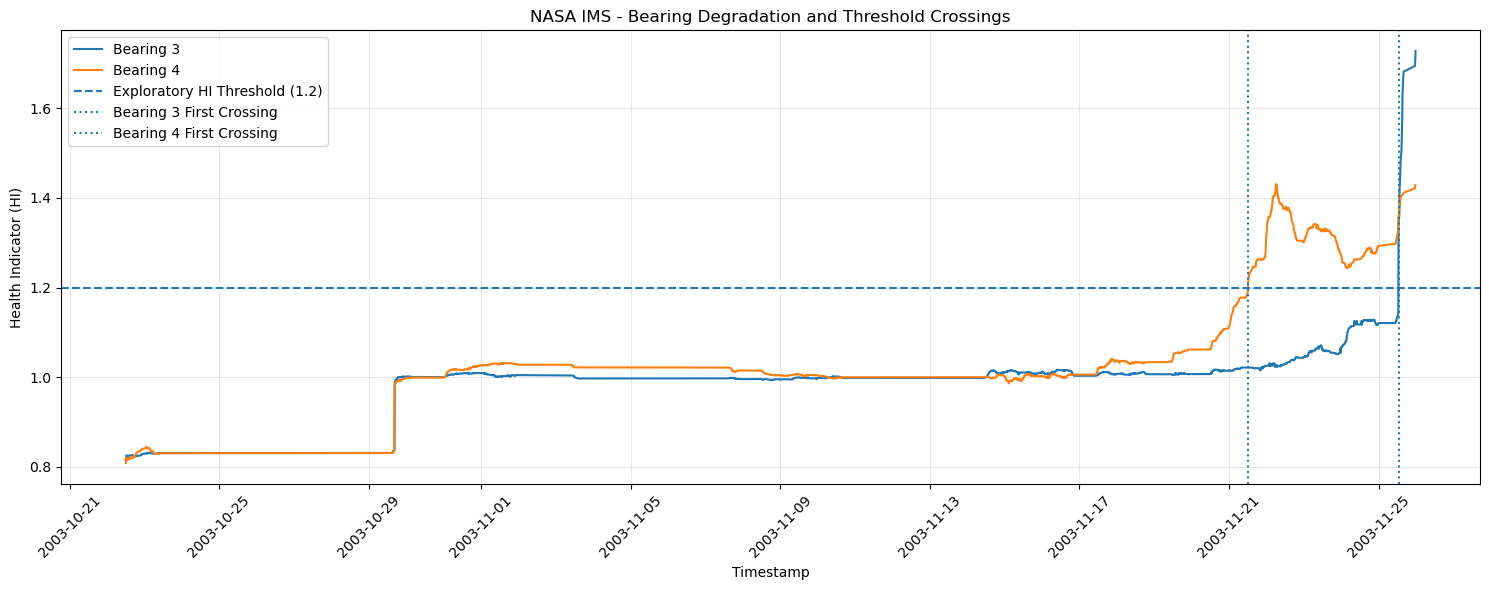

In [128]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    bearing_smooth_df["Timestamp"],
    bearing_smooth_df["Smooth_Bearing_3_HI"],
    label="Bearing 3",
    linewidth=1.5
)

plt.plot(
    bearing_smooth_df["Timestamp"],
    bearing_smooth_df["Smooth_Bearing_4_HI"],
    label="Bearing 4",
    linewidth=1.5
)

plt.axhline(
    y=1.2,
    linestyle="--",
    label="Exploratory HI Threshold (1.2)"
)

plt.axvline(
    x=pd.Timestamp("2003-11-25 12:47:32"),
    linestyle=":",
    label="Bearing 3 First Crossing"
)

plt.axvline(
    x=pd.Timestamp("2003-11-21 12:18:36"),
    linestyle=":",
    label="Bearing 4 First Crossing"
)

plt.xlabel("Timestamp")
plt.ylabel("Health Indicator (HI)")
plt.title("NASA IMS - Bearing Degradation and Threshold Crossings")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Linear Regression-based degradation forecast.

In [131]:
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

# Actual first threshold-crossing timestamps
actual_crossings = {
    "Bearing_3": pd.Timestamp("2003-11-25 12:47:32"),
    "Bearing_4": pd.Timestamp("2003-11-21 12:18:36")
}

# Prepare data
forecast_df = degradation_df.copy()

forecast_df["Elapsed_Hours"] = (
    forecast_df["Timestamp"] -
    forecast_df["Timestamp"].iloc[0]
).dt.total_seconds() / 3600

forecast_df = forecast_df.sort_values("Timestamp").reset_index(drop=True)

# Check the prepared data
print("Dataset shape:", forecast_df.shape)
print("\nColumns:")
print(forecast_df.columns.tolist())

print("\nActual threshold crossings:")
for bearing, timestamp in actual_crossings.items():
    print(bearing, ":", timestamp)

Dataset shape: (2156, 9)

Columns:
['Timestamp', 'Smooth_Bearing_3_HI', 'Smooth_Bearing_4_HI', 'RUL_Proxy_Hours', 'Elapsed_Hours', 'Bearing_3_Rate', 'Bearing_4_Rate', 'Bearing_3_Rate_Smooth', 'Bearing_4_Rate_Smooth']

Actual threshold crossings:
Bearing_3 : 2003-11-25 12:47:32
Bearing_4 : 2003-11-21 12:18:36


# Step 2: Build the forecasting function
This function will:
- Use only historical observations before the selected cut-off.
- Fit a Linear Regression model to the HI trend.
- Estimate when the trend reaches HI = 1.2.
- Compare the predicted crossing with the actual crossing.

In [134]:
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

def forecast_threshold_crossing(
    data,
    hi_column,
    actual_crossing,
    cutoff_fraction,
    threshold=1.2
):
    # Keep observations strictly before actual crossing
    historical_data = data[
        data["Timestamp"] < actual_crossing
    ].copy()

    # Select the historical portion available at this cutoff
    cutoff_index = int(len(historical_data) * cutoff_fraction)
    training_data = historical_data.iloc[:cutoff_index].copy()

    # Need enough observations to estimate a trend
    if len(training_data) < 10:
        return None

    # Fit linear regression using historical data only
    X = training_data[["Elapsed_Hours"]]
    y = training_data[hi_column]

    model = LinearRegression()
    model.fit(X, y)

    # Current HI and time at the forecasting cutoff
    current_hi = y.iloc[-1]
    current_time = X.iloc[-1, 0]

    # Estimated degradation rate
    rate = model.coef_[0]

    # Predict threshold-crossing time
    if rate <= 0 or current_hi >= threshold:
        predicted_hours_remaining = np.nan
        predicted_crossing_time = pd.NaT
    else:
        predicted_hours_remaining = (threshold - current_hi) / rate

        predicted_crossing_time = (
            training_data["Timestamp"].iloc[-1]
            + pd.to_timedelta(predicted_hours_remaining, unit="h")
        )

    # Actual remaining time from the cutoff
    actual_remaining_hours = (
        actual_crossing - training_data["Timestamp"].iloc[-1]
    ).total_seconds() / 3600

    return {
        "Cutoff_Percentage": cutoff_fraction * 100,
        "Training_Samples": len(training_data),
        "Current_HI": current_hi,
        "Estimated_Rate_per_Hour": rate,
        "Predicted_Remaining_Hours": predicted_hours_remaining,
        "Predicted_Crossing_Time": predicted_crossing_time,
        "Actual_Remaining_Hours": actual_remaining_hours,
        "Actual_Crossing_Time": actual_crossing
    }

print("Forecasting function created successfully!")

Forecasting function created successfully!


In [136]:
#Step 3: Run forecasts for both bearings
#Now we'll test five historical cut-off points: 50%, 60%, 70%, 80%, and 90%.
cutoff_points = [0.50, 0.60, 0.70, 0.80, 0.90]

results = []

bearing_config = {
    "Bearing_3": {
        "hi_column": "Smooth_Bearing_3_HI",
        "actual_crossing": actual_crossings["Bearing_3"]
    },
    "Bearing_4": {
        "hi_column": "Smooth_Bearing_4_HI",
        "actual_crossing": actual_crossings["Bearing_4"]
    }
}

for bearing, config in bearing_config.items():

    for cutoff in cutoff_points:

        result = forecast_threshold_crossing(
            data=forecast_df,
            hi_column=config["hi_column"],
            actual_crossing=config["actual_crossing"],
            cutoff_fraction=cutoff
        )

        if result is not None:
            result["Bearing"] = bearing
            results.append(result)

forecast_results = pd.DataFrame(results)

print(forecast_results.round(3).to_string(index=False))

 Cutoff_Percentage  Training_Samples  Current_HI  Estimated_Rate_per_Hour  Predicted_Remaining_Hours       Predicted_Crossing_Time  Actual_Remaining_Hours Actual_Crossing_Time   Bearing
              50.0              1065       1.011                      0.0                    724.812 2003-12-15 20:47:30.500831228                 236.813  2003-11-25 12:47:32 Bearing_3
              60.0              1278       1.012                      0.0                    860.008 2003-12-23 13:03:00.168659768                 187.751  2003-11-25 12:47:32 Bearing_3
              70.0              1491       1.007                      0.0                   1022.873 2004-01-01 10:28:29.511139250                 137.190  2003-11-25 12:47:32 Bearing_3
              80.0              1704       1.020                      0.0                   1057.015 2004-01-04 19:57:50.739021341                  89.843  2003-11-25 12:47:32 Bearing_3
              90.0              1917       1.064                      

In [138]:
def forecast_recent_window(
    data,
    hi_column,
    actual_crossing,
    cutoff_fraction,
    window_size=100,
    threshold=1.2
):
    historical_data = data[
        data["Timestamp"] < actual_crossing
    ].copy()

    cutoff_index = int(len(historical_data) * cutoff_fraction)
    available_data = historical_data.iloc[:cutoff_index].copy()

    if len(available_data) < window_size:
        return None

    # Use only the most recent observations
    training_data = available_data.tail(window_size).copy()

    X = training_data[["Elapsed_Hours"]]
    y = training_data[hi_column]

    model = LinearRegression()
    model.fit(X, y)

    current_hi = y.iloc[-1]
    current_time = training_data["Timestamp"].iloc[-1]
    rate = model.coef_[0]

    if rate <= 0 or current_hi >= threshold:
        predicted_hours = np.nan
        predicted_time = pd.NaT
    else:
        predicted_hours = (threshold - current_hi) / rate
        predicted_time = (
            current_time +
            pd.to_timedelta(predicted_hours, unit="h")
        )

    actual_hours = (
        actual_crossing - current_time
    ).total_seconds() / 3600

    return {
        "Cutoff_Percentage": cutoff_fraction * 100,
        "Training_Samples": len(training_data),
        "Current_HI": current_hi,
        "Rate_per_Hour": rate,
        "Predicted_Remaining_Hours": predicted_hours,
        "Actual_Remaining_Hours": actual_hours,
        "Predicted_Crossing_Time": predicted_time
    }

print("Recent-window forecasting function created!")

Recent-window forecasting function created!


In [140]:
recent_results = []

for bearing, config in bearing_config.items():

    for cutoff in cutoff_points:

        result = forecast_recent_window(
            data=forecast_df,
            hi_column=config["hi_column"],
            actual_crossing=config["actual_crossing"],
            cutoff_fraction=cutoff,
            window_size=100
        )

        if result is not None:
            result["Bearing"] = bearing
            recent_results.append(result)

recent_forecast_df = pd.DataFrame(recent_results)

print(recent_forecast_df.round(4).to_string(index=False))

 Cutoff_Percentage  Training_Samples  Current_HI  Rate_per_Hour  Predicted_Remaining_Hours  Actual_Remaining_Hours       Predicted_Crossing_Time   Bearing
              50.0               100      1.0114        -0.0002                        NaN                236.8128                           NaT Bearing_3
              60.0               100      1.0116        -0.0002                        NaN                187.7506                           NaT Bearing_3
              70.0               100      1.0071        -0.0001                        NaN                137.1903                           NaT Bearing_3
              80.0               100      1.0201         0.0003                   526.8448                 89.8433 2003-12-13 17:47:37.211089991 Bearing_3
              90.0               100      1.0639         0.0015                    88.2958                 51.6767 2003-11-27 01:24:41.034795658 Bearing_3
              50.0               100      0.9992        -0.0002       

In [142]:
# forecast errrors
# Calculate forecast errors
error_df = recent_forecast_df.copy()

error_df["Absolute_Error_Hours"] = (
    error_df["Predicted_Remaining_Hours"]
    - error_df["Actual_Remaining_Hours"]
).abs()

error_df["Error_Percentage"] = (
    error_df["Absolute_Error_Hours"]
    / error_df["Actual_Remaining_Hours"]
) * 100

# Display results
print(
    error_df[
        [
            "Bearing",
            "Cutoff_Percentage",
            "Predicted_Remaining_Hours",
            "Actual_Remaining_Hours",
            "Absolute_Error_Hours",
            "Error_Percentage"
        ]
    ].round(2).to_string(index=False)
)

# Summary for valid forecasts
valid_errors = error_df.dropna(subset=["Absolute_Error_Hours"])

print("\nAverage Absolute Forecast Error:")
print(
    valid_errors.groupby("Bearing")["Absolute_Error_Hours"]
    .mean().round(2)
)

  Bearing  Cutoff_Percentage  Predicted_Remaining_Hours  Actual_Remaining_Hours  Absolute_Error_Hours  Error_Percentage
Bearing_3               50.0                        NaN                  236.81                   NaN               NaN
Bearing_3               60.0                        NaN                  187.75                   NaN               NaN
Bearing_3               70.0                        NaN                  137.19                   NaN               NaN
Bearing_3               80.0                     526.84                   89.84                437.00            486.40
Bearing_3               90.0                      88.30                   51.68                 36.62             70.86
Bearing_4               50.0                        NaN                  268.88                   NaN               NaN
Bearing_4               60.0                        NaN                  150.16                   NaN               NaN
Bearing_4               70.0            

In [144]:
comparison_df = forecast_results.copy()

comparison_df = comparison_df.rename(columns={
    "Predicted_Remaining_Hours": "Full_History_Prediction",
    "Actual_Remaining_Hours": "Actual_Remaining_Hours"
})

comparison_df["Full_History_Error"] = (
    comparison_df["Full_History_Prediction"]
    - comparison_df["Actual_Remaining_Hours"]
).abs()

recent_comparison = recent_forecast_df[
    ["Bearing", "Cutoff_Percentage", "Predicted_Remaining_Hours"]
].rename(columns={
    "Predicted_Remaining_Hours": "Recent_Window_Prediction"
})

comparison_df = comparison_df.merge(
    recent_comparison,
    on=["Bearing", "Cutoff_Percentage"]
)

comparison_df["Recent_Window_Error"] = (
    comparison_df["Recent_Window_Prediction"]
    - comparison_df["Actual_Remaining_Hours"]
).abs()

print(
    comparison_df[
        [
            "Bearing",
            "Cutoff_Percentage",
            "Full_History_Error",
            "Recent_Window_Error"
        ]
    ].round(2).to_string(index=False)
)

  Bearing  Cutoff_Percentage  Full_History_Error  Recent_Window_Error
Bearing_3               50.0              488.00                  NaN
Bearing_3               60.0              672.26                  NaN
Bearing_3               70.0              885.68                  NaN
Bearing_3               80.0              967.17               437.00
Bearing_3               90.0              758.14                36.62
Bearing_4               50.0              272.69                  NaN
Bearing_4               60.0              619.87                  NaN
Bearing_4               70.0              817.59               893.41
Bearing_4               80.0              772.85                39.52
Bearing_4               90.0              686.05               125.62


#Phase 1 — Stable operation
HI changes slowly and remains relatively stable.


#Phase 2 — Accelerated degradation
HI begins increasing more rapidly as degradation progresses.

In [149]:
#Step 5A: Create a piecewise forecasting function
def forecast_piecewise(
    data,
    hi_column,
    actual_crossing,
    cutoff_fraction,
    threshold=1.2,
    min_segment=30
):
    historical = data[
        data["Timestamp"] < actual_crossing
    ].copy().reset_index(drop=True)

    cutoff_index = int(len(historical) * cutoff_fraction)
    available = historical.iloc[:cutoff_index].copy()

    if len(available) < 2 * min_segment:
        return None

    x = available["Elapsed_Hours"].to_numpy()
    y = available[hi_column].to_numpy()

    best_error = np.inf
    best_model = None

    # Search for a historical change point
    for cp in range(min_segment, len(available) - min_segment):

        model = LinearRegression()
        model.fit(x[cp:].reshape(-1, 1), y[cp:])

        predictions = model.predict(x[cp:].reshape(-1, 1))
        error = np.mean((y[cp:] - predictions) ** 2)

        if error < best_error:
            best_error = error
            best_model = model
            best_cp = cp

    current_hi = y[-1]
    current_time = available["Timestamp"].iloc[-1]
    rate = best_model.coef_[0]

    if rate <= 0 or current_hi >= threshold:
        predicted_hours = np.nan
        predicted_time = pd.NaT
    else:
        predicted_hours = (threshold - current_hi) / rate
        predicted_time = (
            current_time +
            pd.to_timedelta(predicted_hours, unit="h")
        )

    actual_hours = (
        actual_crossing - current_time
    ).total_seconds() / 3600

    return {
        "Cutoff_Percentage": cutoff_fraction * 100,
        "Change_Point_Index": best_cp,
        "Current_HI": current_hi,
        "Estimated_Rate_per_Hour": rate,
        "Predicted_Remaining_Hours": predicted_hours,
        "Actual_Remaining_Hours": actual_hours,
        "Predicted_Crossing_Time": predicted_time
    }

print("Piecewise forecasting function created!")

Piecewise forecasting function created!


In [151]:
piecewise_results = []

for bearing, config in bearing_config.items():

    for cutoff in cutoff_points:

        result = forecast_piecewise(
            data=forecast_df,
            hi_column=config["hi_column"],
            actual_crossing=config["actual_crossing"],
            cutoff_fraction=cutoff,
            threshold=1.2
        )

        if result is not None:
            result["Bearing"] = bearing
            piecewise_results.append(result)

piecewise_df = pd.DataFrame(piecewise_results)

print(
    piecewise_df.round(4).to_string(index=False)
)

 Cutoff_Percentage  Change_Point_Index  Current_HI  Estimated_Rate_per_Hour  Predicted_Remaining_Hours  Actual_Remaining_Hours       Predicted_Crossing_Time   Bearing
              50.0                1034      1.0114                   0.0003                   630.1059                236.8128 2003-12-11 22:05:07.381540048 Bearing_3
              60.0                1247      1.0116                   0.0011                   172.0764                187.7506 2003-11-24 21:07:05.084069191 Bearing_3
              70.0                1456      1.0071                   0.0003                   555.6831                137.1903 2003-12-12 23:17:06.059261092 Bearing_3
              80.0                1669      1.0201                  -0.0002                        NaN                 89.8433                           NaT Bearing_3
              90.0                1879      1.0639                   0.0017                    79.2624                 51.6767 2003-11-26 16:22:40.580570562 Bearing_

In [153]:
# Prepare full-history errors
full_errors = forecast_results[
    ["Bearing", "Cutoff_Percentage",
     "Predicted_Remaining_Hours", "Actual_Remaining_Hours"]
].copy()

full_errors["Full_History_Error"] = (
    full_errors["Predicted_Remaining_Hours"]
    - full_errors["Actual_Remaining_Hours"]
).abs()

# Prepare recent-window errors
recent_errors = recent_forecast_df[
    ["Bearing", "Cutoff_Percentage",
     "Predicted_Remaining_Hours"]
].copy()

recent_errors["Recent_Window_Error"] = (
    recent_errors["Predicted_Remaining_Hours"]
    - recent_forecast_df["Actual_Remaining_Hours"]
).abs()

# Prepare piecewise errors
piecewise_errors = piecewise_df[
    ["Bearing", "Cutoff_Percentage",
     "Predicted_Remaining_Hours"]
].copy()

piecewise_errors["Piecewise_Error"] = (
    piecewise_errors["Predicted_Remaining_Hours"]
    - piecewise_df["Actual_Remaining_Hours"]
).abs()

# Combine all models
model_comparison = (
    full_errors[["Bearing", "Cutoff_Percentage", "Full_History_Error"]]
    .merge(
        recent_errors[["Bearing", "Cutoff_Percentage", "Recent_Window_Error"]],
        on=["Bearing", "Cutoff_Percentage"]
    )
    .merge(
        piecewise_errors[["Bearing", "Cutoff_Percentage", "Piecewise_Error"]],
        on=["Bearing", "Cutoff_Percentage"]
    )
)

print(model_comparison.round(2).to_string(index=False))

  Bearing  Cutoff_Percentage  Full_History_Error  Recent_Window_Error  Piecewise_Error
Bearing_3               50.0              488.00                  NaN           393.29
Bearing_3               60.0              672.26                  NaN            15.67
Bearing_3               70.0              885.68                  NaN           418.49
Bearing_3               80.0              967.17               437.00              NaN
Bearing_3               90.0              758.14                36.62            27.59
Bearing_4               50.0              272.69                  NaN              NaN
Bearing_4               60.0              619.87                  NaN           159.88
Bearing_4               70.0              817.59               893.41              NaN
Bearing_4               80.0              772.85                39.52              NaN
Bearing_4               90.0              686.05               125.62           451.88


In [155]:
# Inspect historical data available at each forecasting cut-off

for bearing, config in bearing_config.items():

    historical = forecast_df[
        forecast_df["Timestamp"] < config["actual_crossing"]
    ].copy()

    print(f"\n{bearing}")
    print("-" * 45)

    for cutoff in cutoff_points:

        cutoff_index = int(len(historical) * cutoff)
        available = historical.iloc[:cutoff_index]

        print(
            f"{int(cutoff * 100)}% | "
            f"Samples: {len(available)} | "
            f"Start: {available['Timestamp'].iloc[0]} | "
            f"End: {available['Timestamp'].iloc[-1]} | "
            f"Last HI: {available[config['hi_column']].iloc[-1]:.4f}"
        )


Bearing_3
---------------------------------------------
50% | Samples: 1065 | Start: 2003-10-22 12:06:24 | End: 2003-11-15 15:58:46 | Last HI: 1.0114
60% | Samples: 1278 | Start: 2003-10-22 12:06:24 | End: 2003-11-17 17:02:30 | Last HI: 1.0116
70% | Samples: 1491 | Start: 2003-10-22 12:06:24 | End: 2003-11-19 19:36:07 | Last HI: 1.0071
80% | Samples: 1704 | Start: 2003-10-22 12:06:24 | End: 2003-11-21 18:56:56 | Last HI: 1.0201
90% | Samples: 1917 | Start: 2003-10-22 12:06:24 | End: 2003-11-23 09:06:56 | Last HI: 1.0639

Bearing_4
---------------------------------------------
50% | Samples: 839 | Start: 2003-10-22 12:06:24 | End: 2003-11-10 07:25:58 | Last HI: 0.9992
60% | Samples: 1006 | Start: 2003-10-22 12:06:24 | End: 2003-11-15 06:08:46 | Last HI: 0.9972
70% | Samples: 1174 | Start: 2003-10-22 12:06:24 | End: 2003-11-16 10:08:46 | Last HI: 1.0030
80% | Samples: 1342 | Start: 2003-10-22 12:06:24 | End: 2003-11-18 03:42:30 | Last HI: 1.0361
90% | Samples: 1510 | Start: 2003-10-22 1

In [157]:
def improved_piecewise_forecast(
    data,
    hi_column,
    actual_crossing,
    cutoff_fraction,
    threshold=1.2,
    min_segment=100
):

    historical = data[
        data["Timestamp"] < actual_crossing
    ].copy().reset_index(drop=True)

    cutoff_index = int(len(historical) * cutoff_fraction)
    available = historical.iloc[:cutoff_index].copy()

    if len(available) < 2 * min_segment:
        return None

    x = available["Elapsed_Hours"].to_numpy()
    y = available[hi_column].to_numpy()

    best_error = np.inf
    best_cp = None
    best_first_model = None
    best_second_model = None

    # Search for the best change point
    for cp in range(min_segment, len(available) - min_segment):

        first_model = LinearRegression()
        second_model = LinearRegression()

        first_model.fit(x[:cp].reshape(-1, 1), y[:cp])
        second_model.fit(x[cp:].reshape(-1, 1), y[cp:])

        pred_first = first_model.predict(
            x[:cp].reshape(-1, 1)
        )

        pred_second = second_model.predict(
            x[cp:].reshape(-1, 1)
        )

        # Combined error from both segments
        total_error = (
            np.sum((y[:cp] - pred_first) ** 2)
            + np.sum((y[cp:] - pred_second) ** 2)
        )

        if total_error < best_error:
            best_error = total_error
            best_cp = cp
            best_first_model = first_model
            best_second_model = second_model

    current_hi = y[-1]
    current_time = available["Timestamp"].iloc[-1]

    rate = best_second_model.coef_[0]

    if rate <= 0 or current_hi >= threshold:
        predicted_hours = np.nan
        predicted_time = pd.NaT

    else:
        predicted_hours = (threshold - current_hi) / rate

        predicted_time = (
            current_time
            + pd.to_timedelta(predicted_hours, unit="h")
        )

    actual_hours = (
        actual_crossing - current_time
    ).total_seconds() / 3600

    return {
        "Cutoff_Percentage": cutoff_fraction * 100,
        "Change_Point_Index": best_cp,
        "Current_HI": current_hi,
        "Estimated_Rate_per_Hour": rate,
        "Predicted_Remaining_Hours": predicted_hours,
        "Actual_Remaining_Hours": actual_hours,
        "Predicted_Crossing_Time": predicted_time
    }

print("Improved piecewise forecasting function created!")

Improved piecewise forecasting function created!


In [159]:
improved_results = []

for bearing, config in bearing_config.items():

    for cutoff in cutoff_points:

        result = improved_piecewise_forecast(
            data=forecast_df,
            hi_column=config["hi_column"],
            actual_crossing=config["actual_crossing"],
            cutoff_fraction=cutoff,
            threshold=1.2,
            min_segment=100
        )

        if result is not None:
            result["Bearing"] = bearing
            improved_results.append(result)

improved_piecewise_df = pd.DataFrame(improved_results)

print(
    improved_piecewise_df.round(4).to_string(index=False)
)

 Cutoff_Percentage  Change_Point_Index  Current_HI  Estimated_Rate_per_Hour  Predicted_Remaining_Hours  Actual_Remaining_Hours       Predicted_Crossing_Time   Bearing
              50.0                 168      1.0114                   0.0000                 32090.3843                236.8128 2007-07-14 18:21:49.392094771 Bearing_3
              60.0                 168      1.0116                   0.0000                 11625.3725                187.7506 2005-03-16 02:24:51.154163890 Bearing_3
              70.0                 168      1.0071                   0.0000                 12254.8724                137.1903 2005-04-13 10:28:27.760148898 Bearing_3
              80.0                 168      1.0201                   0.0000                  7971.9560                 89.8433 2004-10-18 22:54:17.538299999 Bearing_3
              90.0                 168      1.0639                   0.0000                  3191.1540                 51.6767 2004-04-04 08:16:10.396771844 Bearing_

In [161]:
# Inspect selected change points

for bearing, config in bearing_config.items():

    print(f"\n{bearing}")
    print("-" * 45)

    historical = forecast_df[
        forecast_df["Timestamp"] < config["actual_crossing"]
    ].copy().reset_index(drop=True)

    cp = 168 if bearing == "Bearing_3" else 167

    print("Change point index:", cp)

    print(
        "Change point timestamp:",
        historical.loc[cp, "Timestamp"]
    )

    print(
        "HI at change point:",
        round(historical.loc[cp, config["hi_column"]], 4)
    )

    print(
        "Final HI at 90% cut-off:",
        round(
            historical.iloc[int(len(historical) * 0.90) - 1][config["hi_column"]],
            4
        )
    )


Bearing_3
---------------------------------------------
Change point index: 168
Change point timestamp: 2003-10-29 16:39:46
HI at change point: 0.9877
Final HI at 90% cut-off: 1.0639

Bearing_4
---------------------------------------------
Change point index: 167
Change point timestamp: 2003-10-29 16:29:46
HI at change point: 0.9798
Final HI at 90% cut-off: 1.0636


In [169]:
def constrained_piecewise_forecast(
    data,
    hi_column,
    actual_crossing,
    cutoff_fraction,
    threshold=1.2,
    min_segment_fraction=0.20
):

    historical = data[
        data["Timestamp"] < actual_crossing
    ].copy().reset_index(drop=True)

    cutoff_index = int(len(historical) * cutoff_fraction)

    available = historical.iloc[:cutoff_index].copy()
    available = available.reset_index(drop=True)

    n = len(available)

    min_segment = int(n * min_segment_fraction)

    X = available[["Elapsed_Hours"]].values
    y = available[hi_column].values

    best_sse = float("inf")
    best_result = None

    for cp in range(min_segment, n - min_segment):

        model1 = LinearRegression()
        model2 = LinearRegression()

        model1.fit(X[:cp], y[:cp])
        model2.fit(X[cp:], y[cp:])

        slope = model2.coef_[0]

        if slope <= 0:
            continue

        pred1 = model1.predict(X[:cp])
        pred2 = model2.predict(X[cp:])

        sse = (
            np.sum((y[:cp] - pred1) ** 2)
            + np.sum((y[cp:] - pred2) ** 2)
        )

        if sse < best_sse:
            best_sse = sse
            best_result = {
                "Change_Point_Index": cp,
                "Change_Point_Time": available.loc[cp, "Timestamp"],
                "Current_HI": y[-1],
                "Estimated_Rate_per_Hour": slope,
                "Predicted_Remaining_Hours": max(
                    0, (threshold - y[-1]) / slope
                ),
                "Actual_Remaining_Hours": (
                    actual_crossing - available["Timestamp"].iloc[-1]
                ).total_seconds() / 3600
            }

    return best_result

In [171]:
constrained_results = []

for bearing, config in bearing_config.items():

    for cutoff in cutoff_points:

        result = constrained_piecewise_forecast(
            data=forecast_df,
            hi_column=config["hi_column"],
            actual_crossing=config["actual_crossing"],
            cutoff_fraction=cutoff,
            threshold=1.2
        )

        if result is not None:
            result["Bearing"] = bearing
            result["Cutoff_Percentage"] = cutoff * 100
            constrained_results.append(result)

constrained_df = pd.DataFrame(constrained_results)

print(constrained_df.round(3).to_string(index=False))

 Change_Point_Index   Change_Point_Time  Current_HI  Estimated_Rate_per_Hour  Predicted_Remaining_Hours  Actual_Remaining_Hours   Bearing  Cutoff_Percentage
                213 2003-10-30 00:09:46       1.011                      0.0                  45318.077                 236.813 Bearing_3               50.0
                388 2003-11-01 03:21:44       1.012                      0.0                   5758.252                 187.751 Bearing_3               60.0
                384 2003-11-01 02:41:44       1.007                      0.0                   6875.141                 137.190 Bearing_3               70.0
                388 2003-11-01 03:21:44       1.020                      0.0                   5044.850                  89.843 Bearing_3               80.0
                407 2003-11-01 06:31:44       1.064                      0.0                   2123.359                  51.677 Bearing_3               90.0
                770 2003-11-09 16:35:58       1.003       

In [173]:
# Inspect actual degradation rates at each cutoff

for bearing, config in bearing_config.items():

    print(f"\n{bearing}")
    print("-" * 50)

    for cutoff in cutoff_points:

        historical = forecast_df[
            forecast_df["Timestamp"] < config["actual_crossing"]
        ].copy()

        cutoff_index = int(len(historical) * cutoff)

        available = historical.iloc[:cutoff_index]

        print(
            f"{cutoff * 100:.0f}% cutoff | "
            f"Last HI: {available[config['hi_column']].iloc[-1]:.4f} | "
            f"Last timestamp: {available['Timestamp'].iloc[-1]}"
        )


Bearing_3
--------------------------------------------------
50% cutoff | Last HI: 1.0114 | Last timestamp: 2003-11-15 15:58:46
60% cutoff | Last HI: 1.0116 | Last timestamp: 2003-11-17 17:02:30
70% cutoff | Last HI: 1.0071 | Last timestamp: 2003-11-19 19:36:07
80% cutoff | Last HI: 1.0201 | Last timestamp: 2003-11-21 18:56:56
90% cutoff | Last HI: 1.0639 | Last timestamp: 2003-11-23 09:06:56

Bearing_4
--------------------------------------------------
50% cutoff | Last HI: 0.9992 | Last timestamp: 2003-11-10 07:25:58
60% cutoff | Last HI: 0.9972 | Last timestamp: 2003-11-15 06:08:46
70% cutoff | Last HI: 1.0030 | Last timestamp: 2003-11-16 10:08:46
80% cutoff | Last HI: 1.0361 | Last timestamp: 2003-11-18 03:42:30
90% cutoff | Last HI: 1.0636 | Last timestamp: 2003-11-20 11:59:03


In [175]:
from sklearn.linear_model import LinearRegression
import numpy as np

def calculate_degradation_rate(data, hi_column):

    X = data[["Elapsed_Hours"]].values
    y = data[hi_column].values

    model = LinearRegression()
    model.fit(X, y)

    return model.coef_[0]


rate_results = []

for bearing, config in bearing_config.items():

    historical = forecast_df[
        forecast_df["Timestamp"] < config["actual_crossing"]
    ].copy().reset_index(drop=True)

    n = len(historical)

    early_data = historical.iloc[:int(n * 0.50)]
    middle_data = historical.iloc[int(n * 0.50):int(n * 0.75)]
    late_data = historical.iloc[int(n * 0.75):]

    hi_column = config["hi_column"]

    early_rate = calculate_degradation_rate(
        early_data, hi_column
    )

    middle_rate = calculate_degradation_rate(
        middle_data, hi_column
    )

    late_rate = calculate_degradation_rate(
        late_data, hi_column
    )

    rate_results.append({
        "Bearing": bearing,
        "Early_Rate": early_rate,
        "Middle_Rate": middle_rate,
        "Late_Rate": late_rate
    })


rate_df = pd.DataFrame(rate_results)

print(rate_df.to_string(index=False))

  Bearing  Early_Rate  Middle_Rate  Late_Rate
Bearing_3    0.000260     0.000011   0.001203
Bearing_4    0.000371     0.000048   0.001303


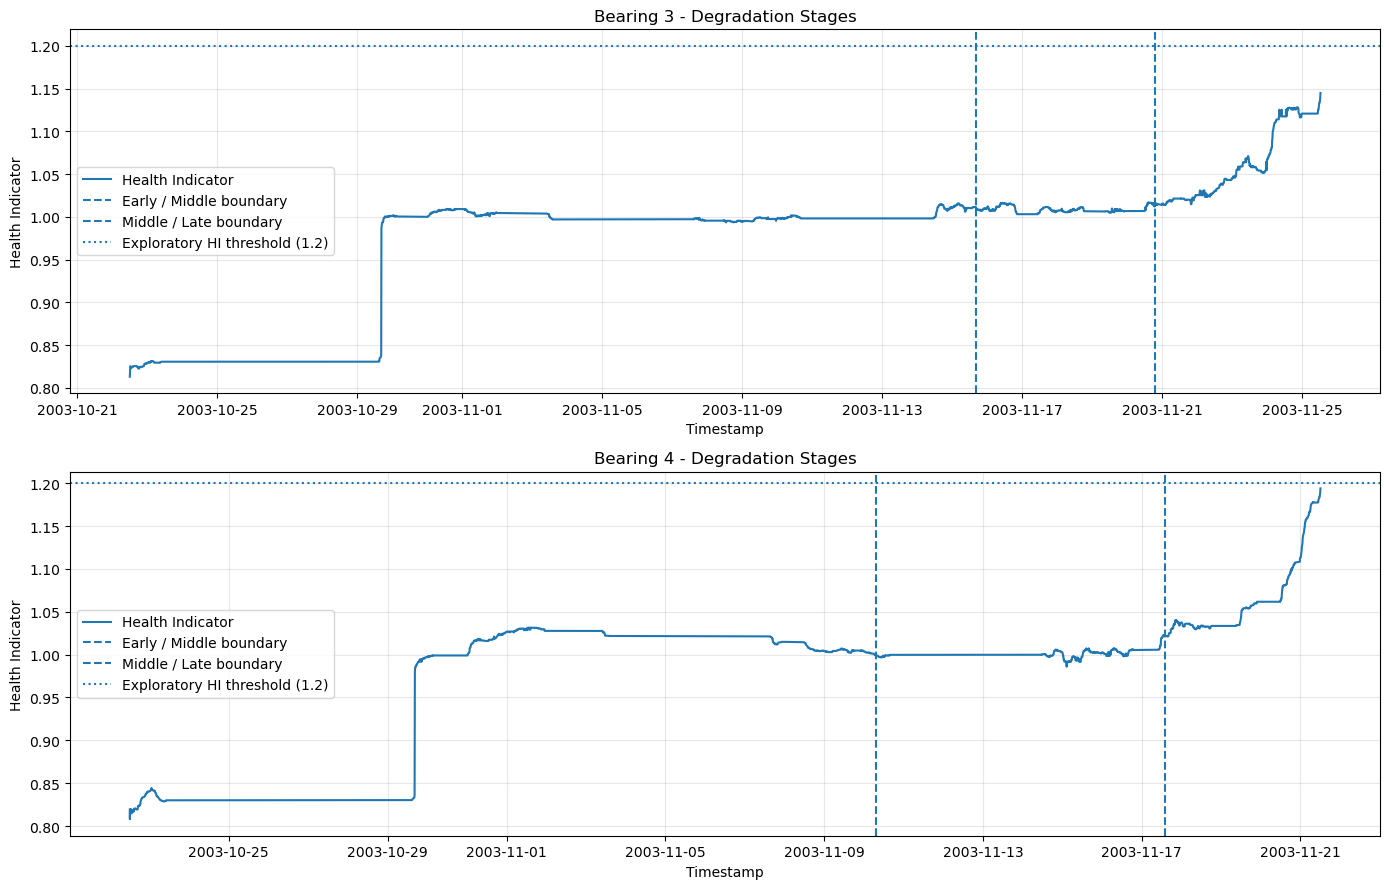

In [177]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

bearing_columns = {
    "Bearing 3": "Smooth_Bearing_3_HI",
    "Bearing 4": "Smooth_Bearing_4_HI"
}

for ax, (bearing, hi_column) in zip(axes, bearing_columns.items()):

    historical = forecast_df[
        forecast_df["Timestamp"] < actual_crossings[
            bearing.replace(" ", "_")
        ]
    ].copy().reset_index(drop=True)

    n = len(historical)

    early_end = int(n * 0.50)
    middle_end = int(n * 0.75)

    ax.plot(
        historical["Timestamp"],
        historical[hi_column],
        label="Health Indicator",
        linewidth=1.5
    )

    ax.axvline(
        historical.loc[early_end, "Timestamp"],
        linestyle="--",
        label="Early / Middle boundary"
    )

    ax.axvline(
        historical.loc[middle_end, "Timestamp"],
        linestyle="--",
        label="Middle / Late boundary"
    )

    ax.axhline(
        1.2,
        linestyle=":",
        label="Exploratory HI threshold (1.2)"
    )

    ax.set_title(bearing + " - Degradation Stages")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Health Indicator")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [179]:
def calculate_rolling_slope(group, hi_column, window=100):

    slopes = [np.nan] * len(group)

    for i in range(window - 1, len(group)):

        segment = group.iloc[i - window + 1:i + 1]

        X = segment[["Elapsed_Hours"]].values
        y = segment[hi_column].values

        model = LinearRegression()
        model.fit(X, y)

        slopes[i] = model.coef_[0]

    return slopes


rolling_rate_df = forecast_df.copy()

rolling_rate_df["B3_Rolling_Rate"] = np.nan
rolling_rate_df["B4_Rolling_Rate"] = np.nan

for bearing, hi_column, rate_column in [
    ("Bearing_3", "Smooth_Bearing_3_HI", "B3_Rolling_Rate"),
    ("Bearing_4", "Smooth_Bearing_4_HI", "B4_Rolling_Rate")
]:

    historical = rolling_rate_df[
        rolling_rate_df["Timestamp"] < actual_crossings[bearing]
    ].copy().reset_index()

    rolling_rate_df.loc[
        historical["index"],
        rate_column
    ] = calculate_rolling_slope(
        historical,
        hi_column,
        window=100
    )

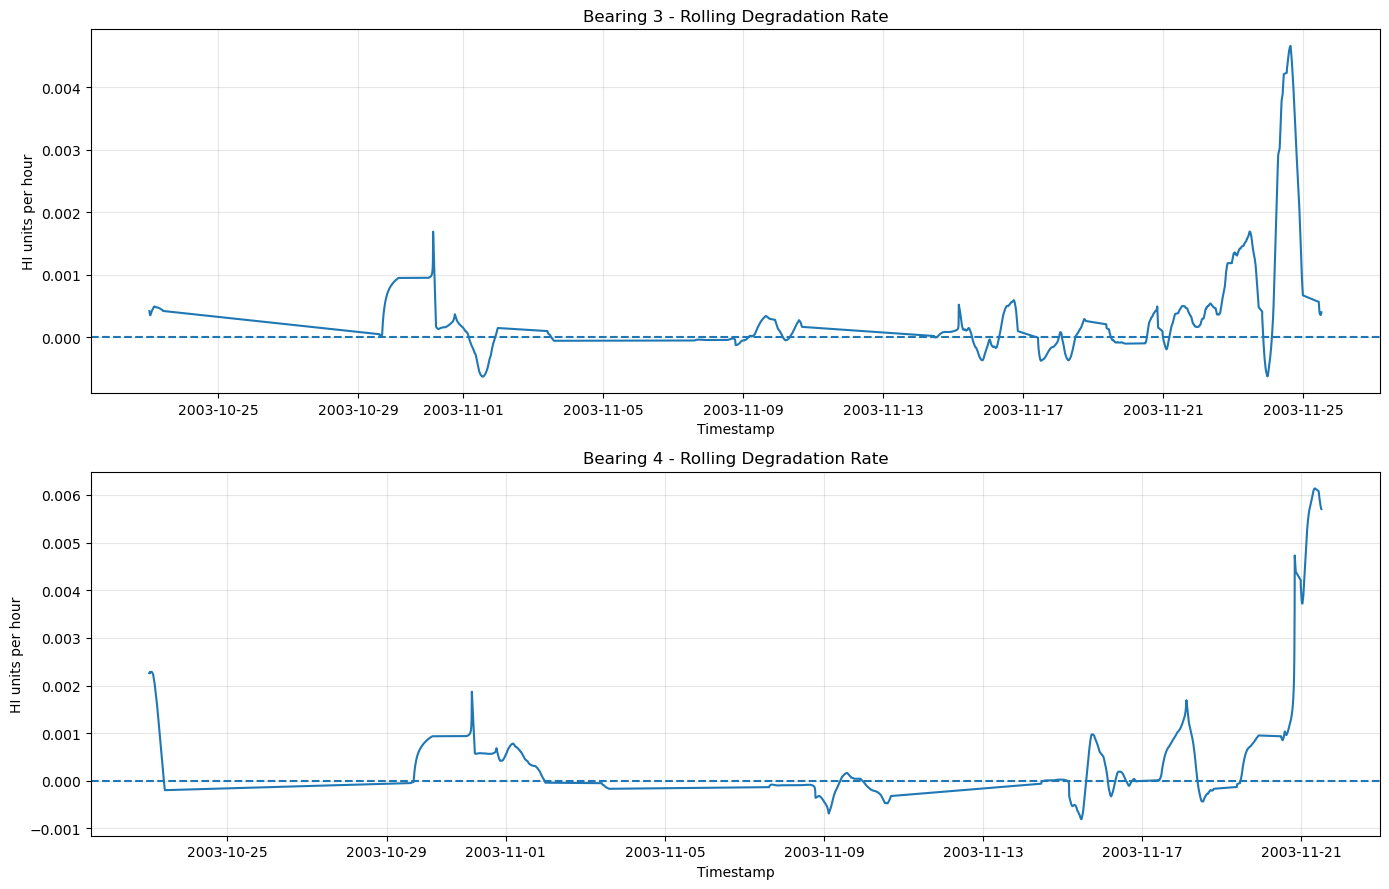

In [181]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

rate_config = [
    ("Bearing 3", "B3_Rolling_Rate"),
    ("Bearing 4", "B4_Rolling_Rate")
]

for ax, (bearing, rate_column) in zip(axes, rate_config):

    plot_data = rolling_rate_df.dropna(
        subset=[rate_column]
    )

    ax.plot(
        plot_data["Timestamp"],
        plot_data[rate_column],
        linewidth=1.5
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(bearing + " - Rolling Degradation Rate")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("HI units per hour")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [183]:
# Calculate rolling acceleration

acceleration_df = rolling_rate_df.copy()

acceleration_df["B3_Acceleration"] = (
    acceleration_df["B3_Rolling_Rate"].diff()
    / acceleration_df["Elapsed_Hours"].diff()
)

acceleration_df["B4_Acceleration"] = (
    acceleration_df["B4_Rolling_Rate"].diff()
    / acceleration_df["Elapsed_Hours"].diff()
)

print(
    acceleration_df[
        [
            "Timestamp",
            "B3_Rolling_Rate",
            "B3_Acceleration",
            "B4_Rolling_Rate",
            "B4_Acceleration"
        ]
    ].tail(10).round(7).to_string(index=False)
)

          Timestamp  B3_Rolling_Rate  B3_Acceleration  B4_Rolling_Rate  B4_Acceleration
2003-11-25 15:17:32              NaN              NaN              NaN              NaN
2003-11-25 15:27:32              NaN              NaN              NaN              NaN
2003-11-25 15:37:32              NaN              NaN              NaN              NaN
2003-11-25 15:47:32              NaN              NaN              NaN              NaN
2003-11-25 15:57:32              NaN              NaN              NaN              NaN
2003-11-25 16:07:32              NaN              NaN              NaN              NaN
2003-11-25 23:13:21              NaN              NaN              NaN              NaN
2003-11-25 23:19:56              NaN              NaN              NaN              NaN
2003-11-25 23:29:56              NaN              NaN              NaN              NaN
2003-11-25 23:39:56              NaN              NaN              NaN              NaN


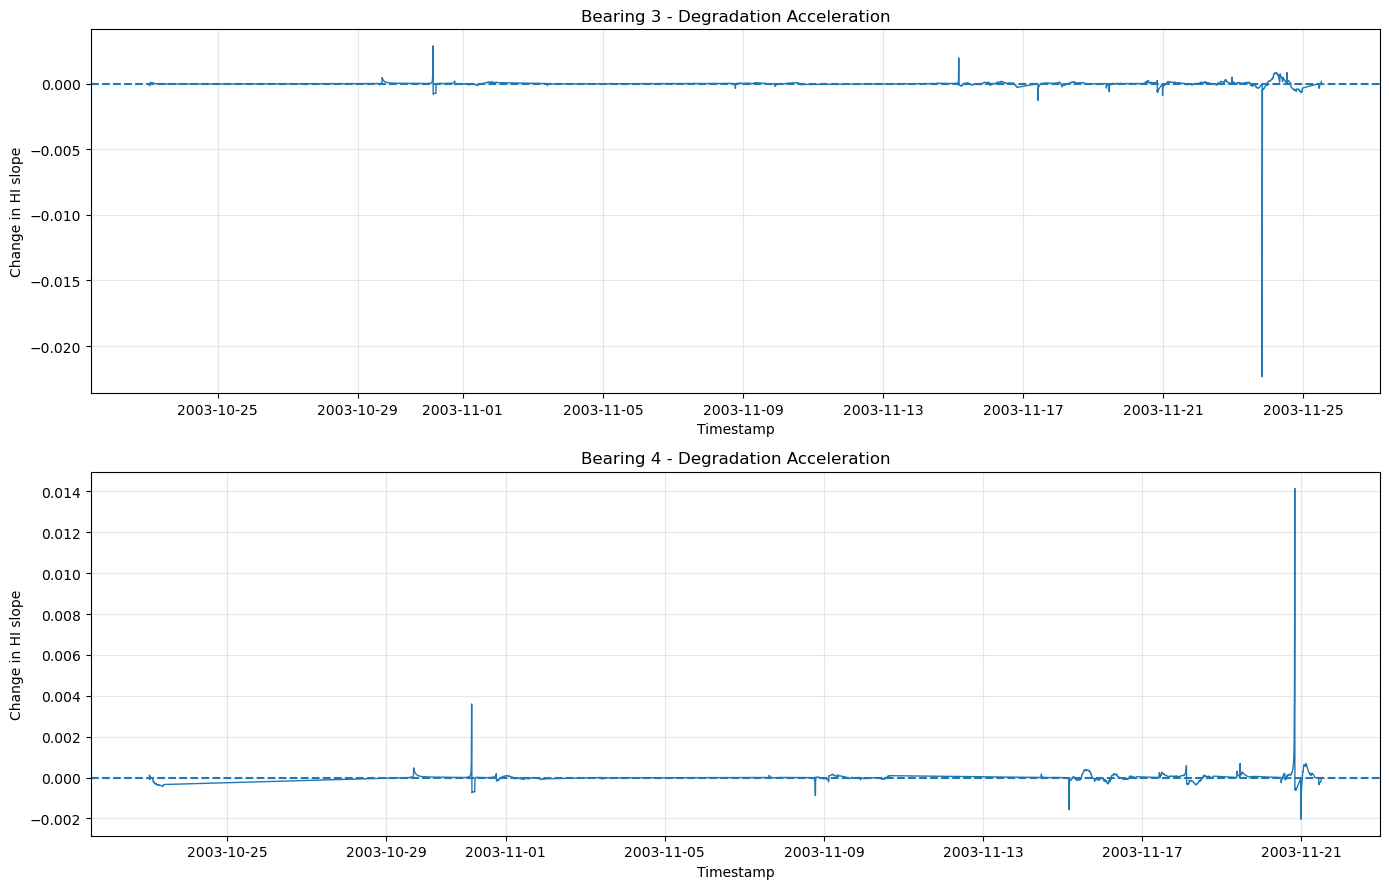

In [185]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

configs = [
    ("Bearing 3", "B3_Acceleration"),
    ("Bearing 4", "B4_Acceleration")
]

for ax, (bearing, column) in zip(axes, configs):

    plot_data = acceleration_df.dropna(subset=[column])

    ax.plot(
        plot_data["Timestamp"],
        plot_data[column],
        linewidth=1
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(bearing + " - Degradation Acceleration")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Change in HI slope")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [187]:
print("Bearing 3 valid rates:",
      acceleration_df["B3_Rolling_Rate"].notna().sum())

print("Bearing 4 valid rates:",
      acceleration_df["B4_Rolling_Rate"].notna().sum())

print("\nLast valid Bearing 3 observations:")
print(
    acceleration_df.dropna(subset=["B3_Rolling_Rate"])
    [["Timestamp", "B3_Rolling_Rate", "B3_Acceleration"]]
    .tail(10).round(7).to_string(index=False)
)

print("\nLast valid Bearing 4 observations:")
print(
    acceleration_df.dropna(subset=["B4_Rolling_Rate"])
    [["Timestamp", "B4_Rolling_Rate", "B4_Acceleration"]]
    .tail(10).round(7).to_string(index=False)
)

Bearing 3 valid rates: 2032
Bearing 4 valid rates: 1579

Last valid Bearing 3 observations:
          Timestamp  B3_Rolling_Rate  B3_Acceleration
2003-11-25 11:07:32         0.000452        -0.000320
2003-11-25 11:17:32         0.000406        -0.000275
2003-11-25 11:27:32         0.000382        -0.000148
2003-11-25 11:37:32         0.000367        -0.000087
2003-11-25 11:47:32         0.000363        -0.000022
2003-11-25 11:57:32         0.000360        -0.000019
2003-11-25 12:07:32         0.000356        -0.000025
2003-11-25 12:17:32         0.000360         0.000023
2003-11-25 12:27:32         0.000372         0.000071
2003-11-25 12:37:32         0.000400         0.000170

Last valid Bearing 4 observations:
          Timestamp  B4_Rolling_Rate  B4_Acceleration
2003-11-21 10:38:36         0.006023        -0.000352
2003-11-21 10:48:36         0.005968        -0.000328
2003-11-21 10:58:36         0.005926        -0.000256
2003-11-21 11:08:36         0.005884        -0.000249
2003-11-

In [189]:
full_rate_df = forecast_df.copy()

full_rate_df["B3_Rolling_Rate_Full"] = calculate_rolling_slope(
    full_rate_df,
    "Smooth_Bearing_3_HI",
    window=100
)

full_rate_df["B4_Rolling_Rate_Full"] = calculate_rolling_slope(
    full_rate_df,
    "Smooth_Bearing_4_HI",
    window=100
)

print("Total observations:", len(full_rate_df))

print(
    "Bearing 3 valid:",
    full_rate_df["B3_Rolling_Rate_Full"].notna().sum()
)

print(
    "Bearing 4 valid:",
    full_rate_df["B4_Rolling_Rate_Full"].notna().sum()
)

Total observations: 2156
Bearing 3 valid: 2057
Bearing 4 valid: 2057


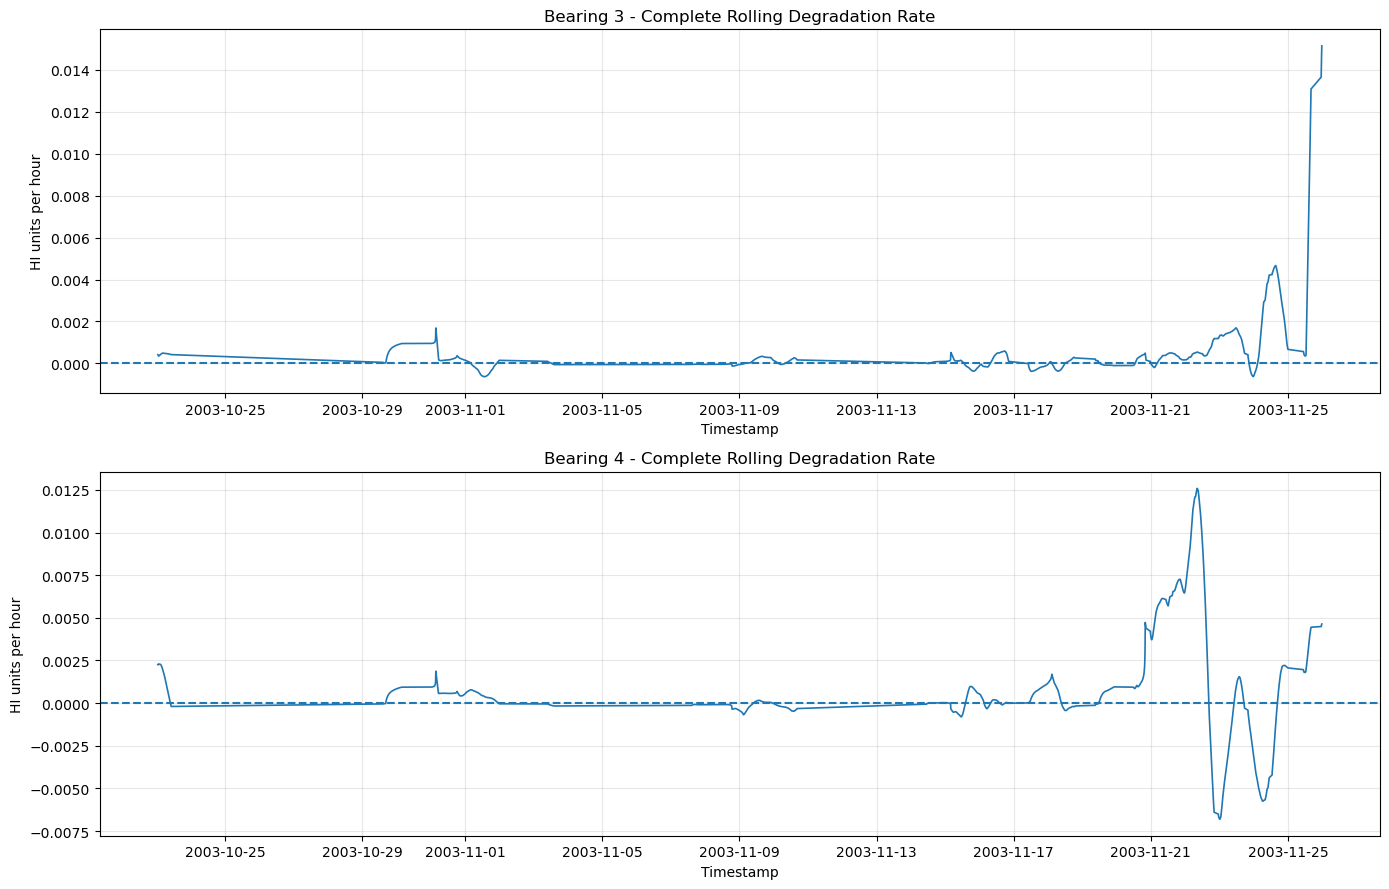

In [191]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

rate_config = [
    ("Bearing 3", "B3_Rolling_Rate_Full"),
    ("Bearing 4", "B4_Rolling_Rate_Full")
]

for ax, (bearing, column) in zip(axes, rate_config):

    ax.plot(
        full_rate_df["Timestamp"],
        full_rate_df[column],
        linewidth=1.2
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(bearing + " - Complete Rolling Degradation Rate")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("HI units per hour")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [193]:
rate_smooth_df = full_rate_df.copy()

rate_columns = [
    "B3_Rolling_Rate_Full",
    "B4_Rolling_Rate_Full"
]

for col in rate_columns:
    rate_smooth_df[f"Smooth_{col}"] = (
        rate_smooth_df[col]
        .rolling(window=25, min_periods=1)
        .median()
    )

print(
    rate_smooth_df[
        [
            "Timestamp",
            "Smooth_B3_Rolling_Rate_Full",
            "Smooth_B4_Rolling_Rate_Full"
        ]
    ].tail(10).round(7).to_string(index=False)
)

          Timestamp  Smooth_B3_Rolling_Rate_Full  Smooth_B4_Rolling_Rate_Full
2003-11-25 15:17:32                     0.002589                     0.002416
2003-11-25 15:27:32                     0.003214                     0.002551
2003-11-25 15:37:32                     0.003810                     0.002684
2003-11-25 15:47:32                     0.004419                     0.002826
2003-11-25 15:57:32                     0.005038                     0.002976
2003-11-25 16:07:32                     0.005659                     0.003128
2003-11-25 23:13:21                     0.006253                     0.003275
2003-11-25 23:19:56                     0.006829                     0.003414
2003-11-25 23:29:56                     0.007381                     0.003544
2003-11-25 23:39:56                     0.007953                     0.003668


In [195]:
rate_smooth_df["B3_Acceleration_Smooth"] = (
    rate_smooth_df["Smooth_B3_Rolling_Rate_Full"].diff()
    / rate_smooth_df["Elapsed_Hours"].diff()
)

rate_smooth_df["B4_Acceleration_Smooth"] = (
    rate_smooth_df["Smooth_B4_Rolling_Rate_Full"].diff()
    / rate_smooth_df["Elapsed_Hours"].diff()
)

In [197]:
rate_smooth_df["B3_Acceleration_Smooth"] = (
    rate_smooth_df["Smooth_B3_Rolling_Rate_Full"].diff()
    / rate_smooth_df["Elapsed_Hours"].diff()
)

rate_smooth_df["B4_Acceleration_Smooth"] = (
    rate_smooth_df["Smooth_B4_Rolling_Rate_Full"].diff()
    / rate_smooth_df["Elapsed_Hours"].diff()
)

print(
    rate_smooth_df[
        [
            "Timestamp",
            "B3_Acceleration_Smooth",
            "B4_Acceleration_Smooth"
        ]
    ].tail(10).round(7).to_string(index=False)
)

          Timestamp  B3_Acceleration_Smooth  B4_Acceleration_Smooth
2003-11-25 15:17:32                0.003169                0.000764
2003-11-25 15:27:32                0.003753                0.000811
2003-11-25 15:37:32                0.003574                0.000794
2003-11-25 15:47:32                0.003655                0.000855
2003-11-25 15:57:32                0.003714                0.000902
2003-11-25 16:07:32                0.003730                0.000909
2003-11-25 23:13:21                0.000084                0.000021
2003-11-25 23:19:56                0.005249                0.001266
2003-11-25 23:29:56                0.003315                0.000784
2003-11-25 23:39:56                0.003434                0.000741


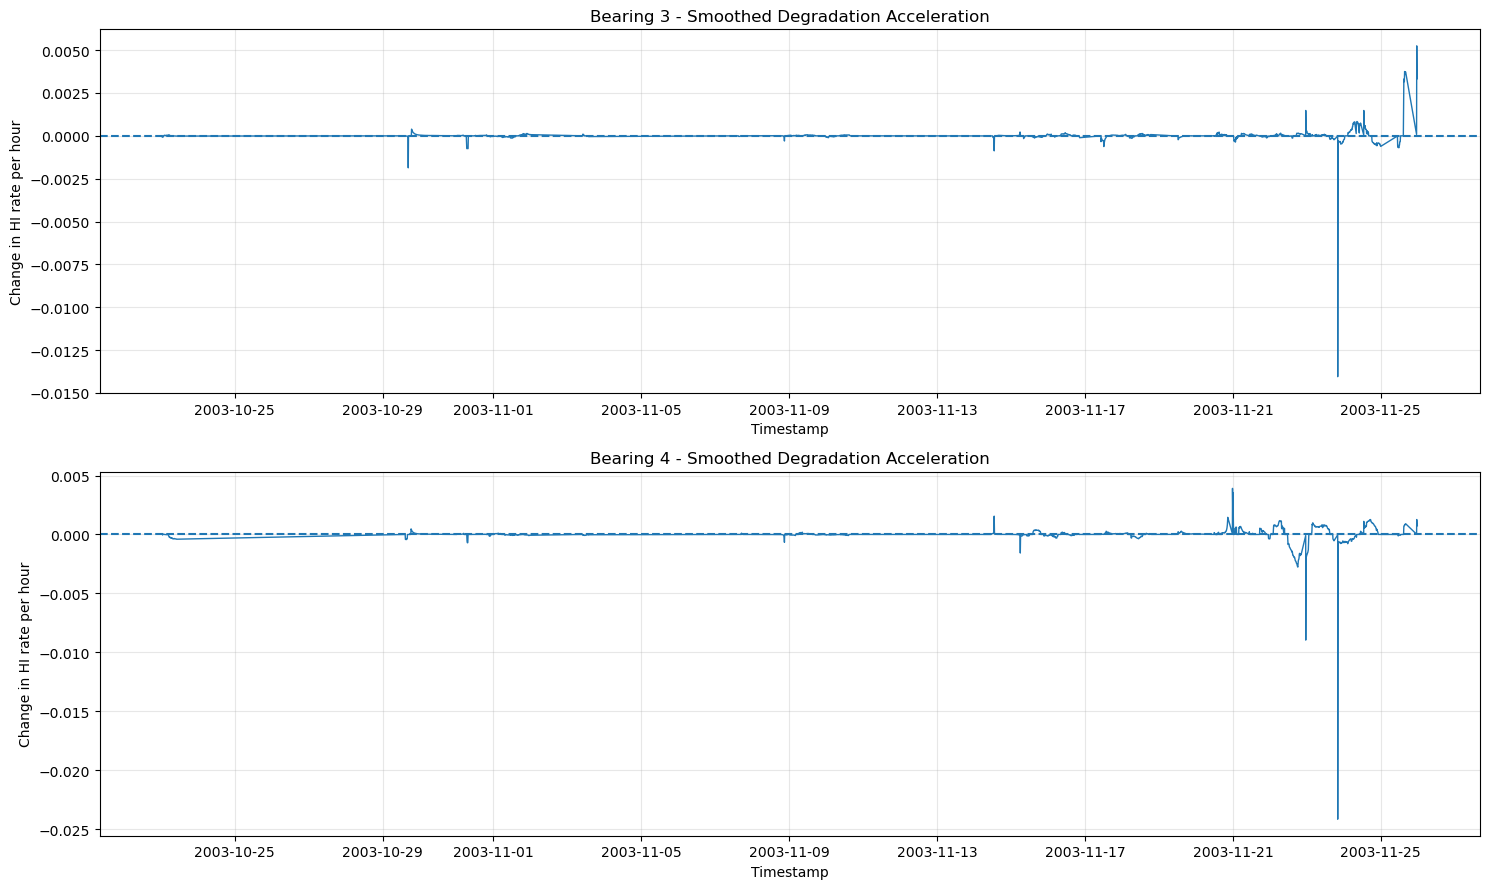

In [199]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

acceleration_config = [
    ("Bearing 3", "B3_Acceleration_Smooth"),
    ("Bearing 4", "B4_Acceleration_Smooth")
]

for ax, (bearing, column) in zip(axes, acceleration_config):

    ax.plot(
        rate_smooth_df["Timestamp"],
        rate_smooth_df[column],
        linewidth=1
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(bearing + " - Smoothed Degradation Acceleration")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Change in HI rate per hour")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [201]:
# Candidate baseline period
baseline_start = pd.Timestamp("2003-10-23")
baseline_end = pd.Timestamp("2003-11-20 23:59:59")

baseline_acc_df = rate_smooth_df[
    (rate_smooth_df["Timestamp"] >= baseline_start) &
    (rate_smooth_df["Timestamp"] <= baseline_end)
].copy()

acceleration_columns = [
    "B3_Acceleration_Smooth",
    "B4_Acceleration_Smooth"
]

baseline_results = []

for col in acceleration_columns:

    values = baseline_acc_df[col].dropna()

    median_value = values.median()

    mad_value = (
        values - median_value
    ).abs().median()

    baseline_results.append({
        "Bearing": col,
        "Median": median_value,
        "MAD": mad_value,
        "Std_Deviation": values.std(),
        "95th_Percentile_Absolute": values.abs().quantile(0.95),
        "Sample_Count": len(values)
    })

baseline_stats_df = pd.DataFrame(baseline_results)

print(
    baseline_stats_df.round(8).to_string(index=False)
)

               Bearing  Median      MAD  Std_Deviation  95th_Percentile_Absolute  Sample_Count
B3_Acceleration_Smooth     0.0 0.000023       0.000096                  0.000129          1517
B4_Acceleration_Smooth     0.0 0.000035       0.000186                  0.000319          1517


In [203]:
# Calculate robust acceleration thresholds

robust_thresholds = {}

for col in acceleration_columns:

    values = baseline_acc_df[col].dropna()

    median_value = values.median()
    mad_value = (values - median_value).abs().median()

    threshold = median_value + (3 * 1.4826 * mad_value)

    bearing = "Bearing 3" if "B3" in col else "Bearing 4"

    robust_thresholds[bearing] = threshold

    print(f"{bearing}")
    print(f"Median: {median_value:.8f}")
    print(f"MAD: {mad_value:.8f}")
    print(f"Positive acceleration threshold: {threshold:.8f}")
    print("-" * 40)

Bearing 3
Median: 0.00000000
MAD: 0.00002299
Positive acceleration threshold: 0.00010226
----------------------------------------
Bearing 4
Median: 0.00000000
MAD: 0.00003531
Positive acceleration threshold: 0.00015705
----------------------------------------


In [205]:
# Detect positive acceleration threshold exceedances

for bearing, column in [
    ("Bearing 3", "B3_Acceleration_Smooth"),
    ("Bearing 4", "B4_Acceleration_Smooth")
]:

    threshold = robust_thresholds[bearing]

    rate_smooth_df[f"{bearing}_Acceleration_Exceedance"] = (
        rate_smooth_df[column] > threshold
    )

    print(f"\n{bearing}")
    print(
        "Total threshold exceedances:",
        rate_smooth_df[
            f"{bearing}_Acceleration_Exceedance"
        ].sum()
    )


Bearing 3
Total threshold exceedances: 206

Bearing 4
Total threshold exceedances: 333


In [207]:
rate_smooth_df["Period"] = pd.cut(
    rate_smooth_df["Timestamp"],
    bins=[
        pd.Timestamp("2003-10-22"),
        pd.Timestamp("2003-11-20"),
        pd.Timestamp("2003-11-23"),
        pd.Timestamp("2003-11-27")
    ],
    labels=["Baseline", "Emerging", "Late stage"],
    include_lowest=True
)

print(
    rate_smooth_df.groupby("Period", observed=False)[
        [
            "Bearing 3_Acceleration_Exceedance",
            "Bearing 4_Acceleration_Exceedance"
        ]
    ].sum()
)

            Bearing 3_Acceleration_Exceedance  \
Period                                          
Baseline                                   60   
Emerging                                   64   
Late stage                                 82   

            Bearing 4_Acceleration_Exceedance  
Period                                         
Baseline                                   73  
Emerging                                  123  
Late stage                                137  


In [209]:
# Compare acceleration exceedance percentages

exceedance_summary = []

for period in ["Baseline", "Emerging", "Late stage"]:

    period_df = rate_smooth_df[
        rate_smooth_df["Period"] == period
    ]

    for bearing, column in [
        ("Bearing 3", "B3_Acceleration_Smooth"),
        ("Bearing 4", "B4_Acceleration_Smooth")
    ]:

        valid_count = period_df[column].notna().sum()

        exceedance_count = period_df[
            f"{bearing}_Acceleration_Exceedance"
        ].sum()

        exceedance_percentage = (
            exceedance_count / valid_count * 100
            if valid_count > 0 else 0
        )

        exceedance_summary.append({
            "Period": period,
            "Bearing": bearing,
            "Valid_Observations": valid_count,
            "Exceedances": exceedance_count,
            "Exceedance_Percentage": exceedance_percentage
        })

exceedance_summary_df = pd.DataFrame(exceedance_summary)

print(
    exceedance_summary_df.round(2).to_string(index=False)
)

    Period   Bearing  Valid_Observations  Exceedances  Exceedance_Percentage
  Baseline Bearing 3                1407           60                   4.26
  Baseline Bearing 4                1407           73                   5.19
  Emerging Bearing 3                 355           64                  18.03
  Emerging Bearing 4                 355          123                  34.65
Late stage Bearing 3                 294           82                  27.89
Late stage Bearing 4                 294          137                  46.60


In [211]:
def find_exceedance_events(df, flag_column, acceleration_column,
                           max_gap_minutes=30):

    temp = df[
        ["Timestamp", flag_column, acceleration_column]
    ].copy().reset_index(drop=True)

    temp["Time_Gap_Minutes"] = (
        temp["Timestamp"].diff().dt.total_seconds() / 60
    )

    # Start a new event after a non-exceedance or a large time gap
    temp["New_Event"] = (
        (~temp[flag_column].shift(fill_value=False)) |
        (temp["Time_Gap_Minutes"] > max_gap_minutes)
    )

    temp["Event_ID"] = temp["New_Event"].cumsum()

    exceedances = temp[temp[flag_column]].copy()

    events = (
        exceedances.groupby("Event_ID")
        .agg(
            Start=("Timestamp", "min"),
            End=("Timestamp", "max"),
            Consecutive_Records=(flag_column, "size"),
            Peak_Acceleration=(acceleration_column, "max")
        )
        .reset_index(drop=True)
    )

    events["Duration_Minutes"] = (
        events["End"] - events["Start"]
    ).dt.total_seconds() / 60

    return events


b3_events = find_exceedance_events(
    rate_smooth_df,
    "Bearing 3_Acceleration_Exceedance",
    "B3_Acceleration_Smooth"
)

b4_events = find_exceedance_events(
    rate_smooth_df,
    "Bearing 4_Acceleration_Exceedance",
    "B4_Acceleration_Smooth"
)

print("BEARING 3 EVENTS")
print(b3_events.sort_values(
    "Consecutive_Records", ascending=False
).head(10).round(7).to_string(index=False))

print("\nBEARING 4 EVENTS")
print(b4_events.sort_values(
    "Consecutive_Records", ascending=False
).head(10).round(7).to_string(index=False))

BEARING 3 EVENTS
              Start                 End  Consecutive_Records  Peak_Acceleration  Duration_Minutes
2003-11-24 02:41:24 2003-11-24 07:01:24                   27           0.000816             260.0
2003-11-24 12:57:32 2003-11-24 15:57:32                   19           0.001479             180.0
2003-11-20 13:59:03 2003-11-20 15:24:03                   18           0.000216              85.0
2003-10-29 18:49:46 2003-10-29 21:09:46                   15           0.000391             140.0
2003-11-16 10:08:46 2003-11-16 12:28:46                   15           0.000177             140.0
2003-11-21 05:34:03 2003-11-21 07:44:03                   14           0.000145             130.0
2003-11-22 17:26:56 2003-11-22 19:26:56                   13           0.000154             120.0
2003-11-22 23:16:56 2003-11-23 00:46:56                   10           0.001480              90.0
2003-11-25 14:47:32 2003-11-25 16:07:32                    9           0.003753              80.0
200

In [213]:
def summarize_events(events, bearing_name):

    events = events.copy()

    events["Period"] = pd.cut(
        events["Start"],
        bins=[
            pd.Timestamp("2003-10-23"),
            pd.Timestamp("2003-11-20 23:59:59"),
            pd.Timestamp("2003-11-23 23:59:59"),
            pd.Timestamp("2003-11-27")
        ],
        labels=["Baseline", "Emerging", "Late stage"],
        include_lowest=True
    )

    summary = (
        events.groupby("Period", observed=False)
        .agg(
            Event_Count=("Duration_Minutes", "count"),
            Longest_Event_Minutes=("Duration_Minutes", "max"),
            Average_Event_Minutes=("Duration_Minutes", "mean"),
            Maximum_Consecutive_Records=("Consecutive_Records", "max")
        )
        .reset_index()
    )

    summary["Bearing"] = bearing_name

    return summary


b3_event_summary = summarize_events(b3_events, "Bearing 3")
b4_event_summary = summarize_events(b4_events, "Bearing 4")

event_summary_df = pd.concat(
    [b3_event_summary, b4_event_summary],
    ignore_index=True
)

print(event_summary_df.round(2).to_string(index=False))

    Period  Event_Count  Longest_Event_Minutes  Average_Event_Minutes  Maximum_Consecutive_Records   Bearing
  Baseline           12                  140.0                  49.58                           18 Bearing 3
  Emerging            9                  130.0                  48.89                           14 Bearing 3
Late stage            6                  260.0                 111.48                           27 Bearing 3
  Baseline           15                  280.0                  51.33                           29 Bearing 4
  Emerging           11                  680.0                 136.36                           69 Bearing 4
Late stage            4                  550.0                 160.00                           56 Bearing 4


In [215]:
monitoring_df = rate_smooth_df[
    [
        "Timestamp",
        "Elapsed_Hours",
        "Smooth_Bearing_3_HI",
        "Smooth_Bearing_4_HI",
        "Smooth_B3_Rolling_Rate_Full",
        "Smooth_B4_Rolling_Rate_Full",
        "B3_Acceleration_Smooth",
        "B4_Acceleration_Smooth",
        "Bearing 3_Acceleration_Exceedance",
        "Bearing 4_Acceleration_Exceedance"
    ]
].copy()

monitoring_df = monitoring_df.rename(columns={
    "Smooth_Bearing_3_HI": "B3_HI",
    "Smooth_Bearing_4_HI": "B4_HI",
    "Smooth_B3_Rolling_Rate_Full": "B3_Degradation_Rate",
    "Smooth_B4_Rolling_Rate_Full": "B4_Degradation_Rate",
    "B3_Acceleration_Smooth": "B3_Acceleration",
    "B4_Acceleration_Smooth": "B4_Acceleration",
    "Bearing 3_Acceleration_Exceedance": "B3_Acceleration_Exceedance",
    "Bearing 4_Acceleration_Exceedance": "B4_Acceleration_Exceedance"
})

print("Monitoring dataset shape:", monitoring_df.shape)
print("\nColumns:")
print(monitoring_df.columns.tolist())

print("\nFirst five records:")
display(monitoring_df.head())

print("\nMissing values:")
print(monitoring_df.isnull().sum())

Monitoring dataset shape: (2156, 10)

Columns:
['Timestamp', 'Elapsed_Hours', 'B3_HI', 'B4_HI', 'B3_Degradation_Rate', 'B4_Degradation_Rate', 'B3_Acceleration', 'B4_Acceleration', 'B3_Acceleration_Exceedance', 'B4_Acceleration_Exceedance']

First five records:


,Timestamp,Elapsed_Hours,B3_HI,B4_HI,B3_Degradation_Rate,B4_Degradation_Rate,B3_Acceleration,B4_Acceleration,B3_Acceleration_Exceedance,B4_Acceleration_Exceedance
0,2003-10-22 12:06:24,0.000000,0.812981,0.819179,NaN,NaN,NaN,NaN,False,False
1,2003-10-22 12:09:13,0.046944,0.814395,0.807986,NaN,NaN,NaN,NaN,False,False
2,2003-10-22 12:14:13,0.130278,0.815809,0.818276,NaN,NaN,NaN,NaN,False,False
3,2003-10-22 12:19:13,0.213611,0.820538,0.818727,NaN,NaN,NaN,NaN,False,False
4,2003-10-22 12:24:13,0.296944,0.825107,0.819179,NaN,NaN,NaN,NaN,False,False



Missing values:
Timestamp                       0
Elapsed_Hours                   0
B3_HI                           0
B4_HI                           0
B3_Degradation_Rate            99
B4_Degradation_Rate            99
B3_Acceleration               100
B4_Acceleration               100
B3_Acceleration_Exceedance      0
B4_Acceleration_Exceedance      0
dtype: int64


In [217]:
from sklearn.preprocessing import MinMaxScaler

monitoring_scaled_df = monitoring_df.copy()

scaler = MinMaxScaler()

b3_columns = [
    "B3_HI",
    "B3_Degradation_Rate",
    "B3_Acceleration"
]

b4_columns = [
    "B4_HI",
    "B4_Degradation_Rate",
    "B4_Acceleration"
]

# Normalize Bearing 3 indicators
monitoring_scaled_df[[f"{col}_Scaled" for col in b3_columns]] = (
    scaler.fit_transform(monitoring_df[b3_columns])
)

# Normalize Bearing 4 indicators
monitoring_scaled_df[[f"{col}_Scaled" for col in b4_columns]] = (
    scaler.fit_transform(monitoring_df[b4_columns])
)

print("Normalization completed!")

display(
    monitoring_scaled_df[
        [
            "Timestamp",
            "B3_HI_Scaled",
            "B3_Degradation_Rate_Scaled",
            "B3_Acceleration_Scaled",
            "B4_HI_Scaled",
            "B4_Degradation_Rate_Scaled",
            "B4_Acceleration_Scaled"
        ]
    ].tail()
)

Normalization completed!


,Timestamp,B3_HI_Scaled,B3_Degradation_Rate_Scaled,B3_Acceleration_Scaled,B4_HI_Scaled,B4_Degradation_Rate_Scaled,B4_Acceleration_Scaled
2151,2003-11-25 16:07:32,0.949521,0.732261,0.921318,0.970513,0.515294,0.893122
2152,2003-11-25 23:13:21,0.963281,0.801495,0.732406,0.985571,0.523144,0.861467
2153,2003-11-25 23:19:56,0.963871,0.868714,1.000000,0.995554,0.530574,0.905843
2154,2003-11-25 23:29:56,0.978193,0.933193,0.899797,0.996922,0.537563,0.888663
2155,2003-11-25 23:39:56,1.000000,1.000000,0.905996,0.997436,0.544166,0.887122


In [219]:
# Create monitoring index using equal conceptual weighting
# HI: 40%, Degradation Rate: 40%, Acceleration: 20%

monitoring_scaled_df["B3_Monitoring_Index"] = (
    0.40 * monitoring_scaled_df["B3_HI_Scaled"] +
    0.40 * monitoring_scaled_df["B3_Degradation_Rate_Scaled"] +
    0.20 * monitoring_scaled_df["B3_Acceleration_Scaled"]
)

monitoring_scaled_df["B4_Monitoring_Index"] = (
    0.40 * monitoring_scaled_df["B4_HI_Scaled"] +
    0.40 * monitoring_scaled_df["B4_Degradation_Rate_Scaled"] +
    0.20 * monitoring_scaled_df["B4_Acceleration_Scaled"]
)

print("Monitoring index calculated!")

display(
    monitoring_scaled_df[
        [
            "Timestamp",
            "B3_Monitoring_Index",
            "B4_Monitoring_Index"
        ]
    ].tail(10).round(4)
)

Monitoring index calculated!


,Timestamp,B3_Monitoring_Index,B4_Monitoring_Index
2146,2003-11-25 15:17:32,0.6869,0.7538
2147,2003-11-25 15:27:32,0.7233,0.7574
2148,2003-11-25 15:37:32,0.7590,0.7605
2149,2003-11-25 15:47:32,0.7920,0.7642
2150,2003-11-25 15:57:32,0.8274,0.7689
2151,2003-11-25 16:07:32,0.8570,0.7729
2152,2003-11-25 23:13:21,0.8524,0.7758
2153,2003-11-25 23:19:56,0.9330,0.7916
2154,2003-11-25 23:29:56,0.9445,0.7915
2155,2003-11-25 23:39:56,0.9812,0.7941


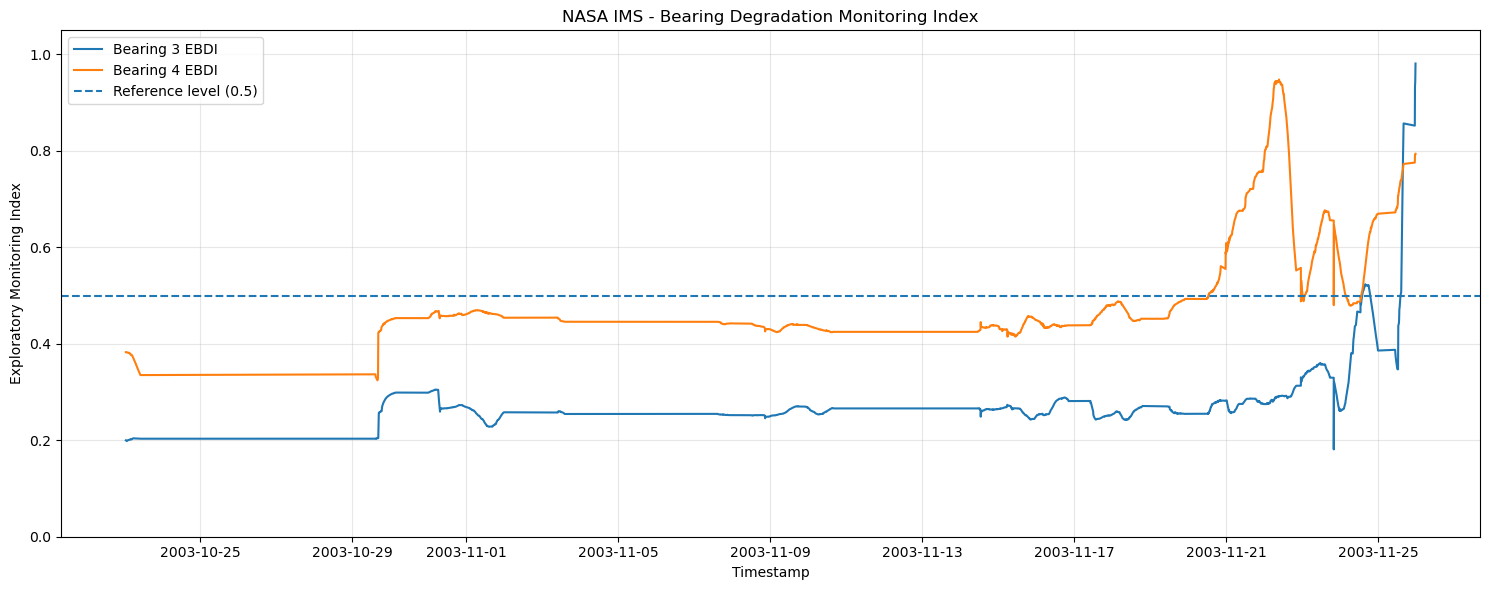

In [221]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    monitoring_scaled_df["Timestamp"],
    monitoring_scaled_df["B3_Monitoring_Index"],
    label="Bearing 3 EBDI",
    linewidth=1.5
)

plt.plot(
    monitoring_scaled_df["Timestamp"],
    monitoring_scaled_df["B4_Monitoring_Index"],
    label="Bearing 4 EBDI",
    linewidth=1.5
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Reference level (0.5)"
)

plt.title("NASA IMS - Bearing Degradation Monitoring Index")
plt.xlabel("Timestamp")
plt.ylabel("Exploratory Monitoring Index")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [223]:
# Keep original EBDI values unchanged
ebdi_smooth_df = monitoring_scaled_df[
    [
        "Timestamp",
        "Elapsed_Hours",
        "B3_Monitoring_Index",
        "B4_Monitoring_Index"
    ]
].copy()

# Rolling median: reduce isolated spikes
for col in ["B3_Monitoring_Index", "B4_Monitoring_Index"]:

    ebdi_smooth_df[f"{col}_Median"] = (
        ebdi_smooth_df[col]
        .rolling(window=25, min_periods=1)
        .median()
    )

# EMA: highlight gradual changes
for col in ["B3_Monitoring_Index", "B4_Monitoring_Index"]:

    ebdi_smooth_df[f"{col}_EMA"] = (
        ebdi_smooth_df[f"{col}_Median"]
        .ewm(span=25, adjust=False)
        .mean()
    )

print("EBDI smoothing completed!")

display(ebdi_smooth_df.tail(10).round(4))

EBDI smoothing completed!


,Timestamp,Elapsed_Hours,B3_Monitoring_Index,B4_Monitoring_Index,B3_Monitoring_Index_Median,B4_Monitoring_Index_Median,B3_Monitoring_Index_EMA,B4_Monitoring_Index_EMA
2146,2003-11-25 15:17:32,819.1856,0.6869,0.7538,0.4485,0.7194,0.4144,0.6844
2147,2003-11-25 15:27:32,819.3522,0.7233,0.7574,0.4719,0.7237,0.4188,0.6874
2148,2003-11-25 15:37:32,819.5189,0.7590,0.7605,0.4751,0.7259,0.4232,0.6904
2149,2003-11-25 15:47:32,819.6856,0.7920,0.7642,0.4839,0.7289,0.4278,0.6933
2150,2003-11-25 15:57:32,819.8522,0.8274,0.7689,0.4905,0.7339,0.4326,0.6965
2151,2003-11-25 16:07:32,820.0189,0.8570,0.7729,0.4981,0.7371,0.4377,0.6996
2152,2003-11-25 23:13:21,827.1158,0.8524,0.7758,0.5020,0.7385,0.4426,0.7026
2153,2003-11-25 23:19:56,827.2256,0.9330,0.7916,0.5051,0.7389,0.4474,0.7054
2154,2003-11-25 23:29:56,827.3922,0.9445,0.7915,0.5065,0.7389,0.4520,0.7079
2155,2003-11-25 23:39:56,827.5589,0.9812,0.7941,0.5508,0.7390,0.4596,0.7103


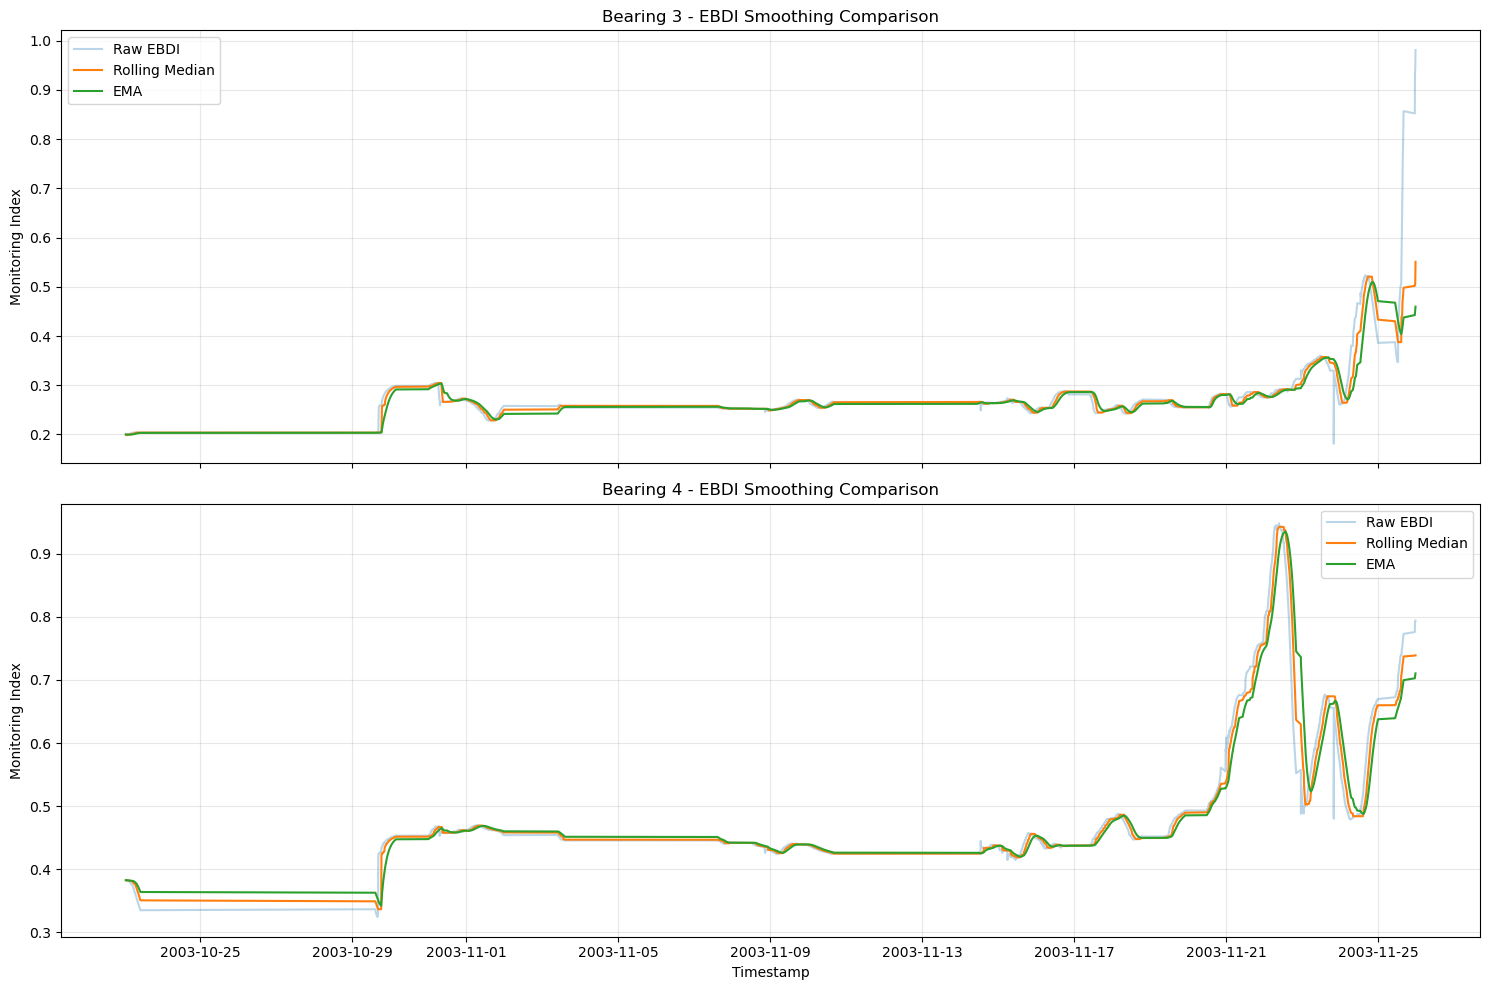

In [225]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# Bearing 3
axes[0].plot(
    ebdi_smooth_df["Timestamp"],
    ebdi_smooth_df["B3_Monitoring_Index"],
    alpha=0.3,
    label="Raw EBDI"
)

axes[0].plot(
    ebdi_smooth_df["Timestamp"],
    ebdi_smooth_df["B3_Monitoring_Index_Median"],
    label="Rolling Median"
)

axes[0].plot(
    ebdi_smooth_df["Timestamp"],
    ebdi_smooth_df["B3_Monitoring_Index_EMA"],
    label="EMA"
)

axes[0].set_title("Bearing 3 - EBDI Smoothing Comparison")
axes[0].set_ylabel("Monitoring Index")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Bearing 4
axes[1].plot(
    ebdi_smooth_df["Timestamp"],
    ebdi_smooth_df["B4_Monitoring_Index"],
    alpha=0.3,
    label="Raw EBDI"
)

axes[1].plot(
    ebdi_smooth_df["Timestamp"],
    ebdi_smooth_df["B4_Monitoring_Index_Median"],
    label="Rolling Median"
)

axes[1].plot(
    ebdi_smooth_df["Timestamp"],
    ebdi_smooth_df["B4_Monitoring_Index_EMA"],
    label="EMA"
)

axes[1].set_title("Bearing 4 - EBDI Smoothing Comparison")
axes[1].set_ylabel("Monitoring Index")
axes[1].set_xlabel("Timestamp")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [227]:
# Select features for NASA IMS anomaly detection

nasa_features = [
    "B3_HI",
    "B4_HI",
    "B3_Degradation_Rate",
    "B4_Degradation_Rate",
    "B3_Acceleration",
    "B4_Acceleration"
]

nasa_training_df = monitoring_df[nasa_features].copy()

print("Training dataset shape:", nasa_training_df.shape)

print("\nMissing values:")
print(nasa_training_df.isnull().sum())

display(nasa_training_df.head())

Training dataset shape: (2156, 6)

Missing values:
B3_HI                    0
B4_HI                    0
B3_Degradation_Rate     99
B4_Degradation_Rate     99
B3_Acceleration        100
B4_Acceleration        100
dtype: int64


,B3_HI,B4_HI,B3_Degradation_Rate,B4_Degradation_Rate,B3_Acceleration,B4_Acceleration
0,0.812981,0.819179,NaN,NaN,NaN,NaN
1,0.814395,0.807986,NaN,NaN,NaN,NaN
2,0.815809,0.818276,NaN,NaN,NaN,NaN
3,0.820538,0.818727,NaN,NaN,NaN,NaN
4,0.825107,0.819179,NaN,NaN,NaN,NaN


In [229]:
# Select baseline operating data

baseline_start = pd.Timestamp("2003-10-22")
baseline_end = pd.Timestamp("2003-11-20 23:59:59")

baseline_nasa_df = monitoring_df[
    (monitoring_df["Timestamp"] >= baseline_start) &
    (monitoring_df["Timestamp"] <= baseline_end)
].copy()

# Select only the six model features
X_baseline = baseline_nasa_df[nasa_features].copy()

# Remove rows containing NaN values
X_baseline = X_baseline.dropna()

print("Baseline dataset shape:", X_baseline.shape)

print("\nBaseline date range:")
print(baseline_nasa_df["Timestamp"].min())
print(baseline_nasa_df["Timestamp"].max())

print("\nRemaining missing values:")
print(X_baseline.isnull().sum())

display(X_baseline.head())

Baseline dataset shape: (1517, 6)

Baseline date range:
2003-10-22 12:06:24
2003-11-20 23:54:03

Remaining missing values:
B3_HI                  0
B4_HI                  0
B3_Degradation_Rate    0
B4_Degradation_Rate    0
B3_Acceleration        0
B4_Acceleration        0
dtype: int64


,B3_HI,B4_HI,B3_Degradation_Rate,B4_Degradation_Rate,B3_Acceleration,B4_Acceleration
100,0.83015,0.842906,0.000405,0.002269,-0.000078,0.000056
101,0.83015,0.844347,0.000392,0.002261,-0.000078,-0.000049
102,0.83015,0.842906,0.000381,0.002266,-0.000065,0.000031
103,0.83015,0.842906,0.000370,0.002271,-0.000065,0.000031
104,0.83015,0.841858,0.000368,0.002274,-0.000014,0.000022


In [231]:
from sklearn.ensemble import IsolationForest

# Create the Isolation Forest model
nasa_model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)

# Train using baseline data
nasa_model.fit(X_baseline)

# Predict baseline observations
baseline_predictions = nasa_model.predict(X_baseline)

# Count normal and anomalous observations
unique, counts = np.unique(
    baseline_predictions,
    return_counts=True
)

print("NASA Isolation Forest training completed!")

for label, count in zip(unique, counts):
    status = "Normal" if label == 1 else "Anomaly"
    print(f"{status}: {count}")

print("\nBaseline anomaly percentage:",
      round((baseline_predictions == -1).mean() * 100, 2), "%")

NASA Isolation Forest training completed!
Anomaly: 46
Normal: 1471

Baseline anomaly percentage: 3.03 %


In [233]:
# Prepare the complete NASA dataset for testing

X_all = monitoring_df[nasa_features].copy()

# Keep only rows with complete features
valid_mask = X_all.notna().all(axis=1)

X_valid = X_all.loc[valid_mask].copy()

# Predict anomalies
all_predictions = nasa_model.predict(X_valid)

# Calculate anomaly scores
anomaly_scores = nasa_model.decision_function(X_valid)

# Create results dataframe
nasa_results_df = monitoring_df.loc[valid_mask, ["Timestamp"]].copy()

nasa_results_df["Anomaly_Prediction"] = all_predictions
nasa_results_df["Anomaly_Score"] = anomaly_scores

nasa_results_df["Status"] = nasa_results_df[
    "Anomaly_Prediction"
].map({
    1: "Normal",
    -1: "Anomaly"
})

print("NASA model testing completed!")

print("\nPrediction summary:")
print(nasa_results_df["Status"].value_counts())

print("\nAnomaly percentage:",
      round((all_predictions == -1).mean() * 100, 2), "%")

display(nasa_results_df.tail(10))

NASA model testing completed!

Prediction summary:
Status
Normal     1715
Anomaly     341
Name: count, dtype: int64

Anomaly percentage: 16.59 %


,Timestamp,Anomaly_Prediction,Anomaly_Score,Status
2146,2003-11-25 15:17:32,-1,-0.084323,Anomaly
2147,2003-11-25 15:27:32,-1,-0.086274,Anomaly
2148,2003-11-25 15:37:32,-1,-0.084810,Anomaly
2149,2003-11-25 15:47:32,-1,-0.087252,Anomaly
2150,2003-11-25 15:57:32,-1,-0.088476,Anomaly
2151,2003-11-25 16:07:32,-1,-0.088476,Anomaly
2152,2003-11-25 23:13:21,-1,-0.003576,Anomaly
2153,2003-11-25 23:19:56,-1,-0.097104,Anomaly
2154,2003-11-25 23:29:56,-1,-0.085786,Anomaly
2155,2003-11-25 23:39:56,-1,-0.084243,Anomaly


In [235]:
# Combine anomaly predictions with EBDI monitoring indicators

nasa_evaluation_df = nasa_results_df.merge(
    ebdi_smooth_df[
        [
            "Timestamp",
            "B3_Monitoring_Index",
            "B4_Monitoring_Index",
            "B3_Monitoring_Index_EMA",
            "B4_Monitoring_Index_EMA"
        ]
    ],
    on="Timestamp",
    how="left"
)

# Compare EBDI during normal and anomalous observations
ebdi_comparison = nasa_evaluation_df.groupby("Status")[
    [
        "B3_Monitoring_Index",
        "B4_Monitoring_Index",
        "B3_Monitoring_Index_EMA",
        "B4_Monitoring_Index_EMA"
    ]
].mean()

print("Average EBDI comparison:")
display(ebdi_comparison)

print("\nAnomaly observations:")
display(
    nasa_evaluation_df[
        nasa_evaluation_df["Status"] == "Anomaly"
    ].tail(10)
)

Average EBDI comparison:


,B3_Monitoring_Index,B4_Monitoring_Index,B3_Monitoring_Index_EMA,B4_Monitoring_Index_EMA
Status,,,,
Anomaly,0.345486,0.629644,0.329910,0.630669
Normal,0.268627,0.482938,0.265989,0.477931



Anomaly observations:


,Timestamp,Anomaly_Prediction,Anomaly_Score,Status,B3_Monitoring_Index,B4_Monitoring_Index,B3_Monitoring_Index_EMA,B4_Monitoring_Index_EMA
2046,2003-11-25 15:17:32,-1,-0.084323,Anomaly,0.686877,0.753816,0.414411,0.684387
2047,2003-11-25 15:27:32,-1,-0.086274,Anomaly,0.723263,0.757374,0.418831,0.687414
2048,2003-11-25 15:37:32,-1,-0.084810,Anomaly,0.758970,0.760510,0.423161,0.690372
2049,2003-11-25 15:47:32,-1,-0.087252,Anomaly,0.792032,0.764154,0.427830,0.693337
2050,2003-11-25 15:57:32,-1,-0.088476,Anomaly,0.827432,0.768875,0.432650,0.696457
2051,2003-11-25 16:07:32,-1,-0.088476,Anomaly,0.856976,0.772947,0.437687,0.699585
2052,2003-11-25 23:13:21,-1,-0.003576,Anomaly,0.852392,0.775779,0.442633,0.702580
2053,2003-11-25 23:19:56,-1,-0.097104,Anomaly,0.933034,0.791620,0.447439,0.705371
2054,2003-11-25 23:29:56,-1,-0.085786,Anomaly,0.944514,0.791527,0.451985,0.707948
2055,2003-11-25 23:39:56,-1,-0.084243,Anomaly,0.981199,0.794065,0.459584,0.710335


In [237]:
# Separate baseline and post-baseline observations

baseline_end = pd.Timestamp("2003-11-20 23:59:59")

nasa_evaluation_df["Data_Period"] = np.where(
    nasa_evaluation_df["Timestamp"] <= baseline_end,
    "Baseline",
    "Post-Baseline"
)

# Count normal and anomalous observations
period_summary = pd.crosstab(
    nasa_evaluation_df["Data_Period"],
    nasa_evaluation_df["Status"]
)

# Calculate anomaly percentage
period_summary["Anomaly_Percentage"] = (
    period_summary.get("Anomaly", 0) /
    period_summary.sum(axis=1).clip(lower=1) * 100
)

print("Anomaly detection by period:")
display(period_summary)

Anomaly detection by period:


Status,Anomaly,Normal,Anomaly_Percentage
Data_Period,,,
Baseline,46,1471,3.032301
Post-Baseline,295,244,54.730983


In [241]:
import joblib
from pathlib import Path

# Define project directory
project_path = Path(
    r"C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance"
)

# Create model directory
models_path = project_path / "results" / "models"
models_path.mkdir(parents=True, exist_ok=True)

# Save NASA Isolation Forest model
nasa_model_file = models_path / "nasa_ims_isolation_forest.pkl"
joblib.dump(nasa_model, nasa_model_file)

# Save feature configuration
nasa_features_file = models_path / "nasa_ims_features.pkl"
joblib.dump(nasa_features, nasa_features_file)

print("NASA model saved successfully!")
print("Model:", nasa_model_file)
print("Features:", nasa_features_file)

NASA model saved successfully!
Model: C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\models\nasa_ims_isolation_forest.pkl
Features: C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\models\nasa_ims_features.pkl


In [243]:
import joblib
import numpy as np

# Load saved NASA model and features
loaded_nasa_model = joblib.load(nasa_model_file)
loaded_nasa_features = joblib.load(nasa_features_file)

# Generate predictions using the loaded model
loaded_predictions = loaded_nasa_model.predict(X_valid)

# Compare with original predictions
print("Original and loaded predictions match:",
      np.array_equal(all_predictions, loaded_predictions))

print("Loaded model:", type(loaded_nasa_model).__name__)
print("Loaded features:", loaded_nasa_features)
print("Total predictions:", len(loaded_predictions))

Original and loaded predictions match: True
Loaded model: IsolationForest
Loaded features: ['B3_HI', 'B4_HI', 'B3_Degradation_Rate', 'B4_Degradation_Rate', 'B3_Acceleration', 'B4_Acceleration']
Total predictions: 2056


In [245]:
# Create final NASA IMS evaluation dataset

final_nasa_evaluation_df = monitoring_df.merge(
    nasa_evaluation_df[
        [
            "Timestamp",
            "Anomaly_Prediction",
            "Anomaly_Score",
            "Status",
            "B3_Monitoring_Index",
            "B4_Monitoring_Index",
            "B3_Monitoring_Index_EMA",
            "B4_Monitoring_Index_EMA"
        ]
    ],
    on="Timestamp",
    how="left"
)

# Add baseline / post-baseline information
baseline_end = pd.Timestamp("2003-11-20 23:59:59")

final_nasa_evaluation_df["Data_Period"] = np.where(
    final_nasa_evaluation_df["Timestamp"] <= baseline_end,
    "Baseline",
    "Post-Baseline"
)

# Save evaluation dataset
evaluation_file = (
    project_path / "results" / "nasa_ims_anomaly_evaluation.csv"
)

evaluation_file.parent.mkdir(parents=True, exist_ok=True)

final_nasa_evaluation_df.to_csv(
    evaluation_file,
    index=False
)

print("NASA evaluation dataset saved successfully!")
print("Dataset shape:", final_nasa_evaluation_df.shape)
print("File location:", evaluation_file)

display(final_nasa_evaluation_df.tail())

NASA evaluation dataset saved successfully!
Dataset shape: (2156, 18)
File location: C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\nasa_ims_anomaly_evaluation.csv


,Timestamp,Elapsed_Hours,B3_HI,B4_HI,B3_Degradation_Rate,B4_Degradation_Rate,B3_Acceleration,B4_Acceleration,B3_Acceleration_Exceedance,B4_Acceleration_Exceedance,Anomaly_Prediction,Anomaly_Score,Status,B3_Monitoring_Index,B4_Monitoring_Index,B3_Monitoring_Index_EMA,B4_Monitoring_Index_EMA,Data_Period
2151,2003-11-25 16:07:32,820.018889,1.682068,1.411910,0.005660,0.003128,0.003730,0.000909,True,True,-1.0,-0.088476,Anomaly,0.856976,0.772947,0.437687,0.699585,Post-Baseline
2152,2003-11-25 23:13:21,827.115833,1.694662,1.421280,0.006253,0.003275,0.000084,0.000021,False,False,-1.0,-0.003576,Anomaly,0.852392,0.775779,0.442633,0.702580,Post-Baseline
2153,2003-11-25 23:19:56,827.225556,1.695202,1.427492,0.006829,0.003414,0.005249,0.001266,True,True,-1.0,-0.097104,Anomaly,0.933034,0.791620,0.447439,0.705371,Post-Baseline
2154,2003-11-25 23:29:56,827.392222,1.708311,1.428343,0.007381,0.003544,0.003315,0.000784,True,True,-1.0,-0.085786,Anomaly,0.944514,0.791527,0.451985,0.707948,Post-Baseline
2155,2003-11-25 23:39:56,827.558889,1.728271,1.428663,0.007953,0.003668,0.003434,0.000741,True,True,-1.0,-0.084243,Anomaly,0.981199,0.794065,0.459584,0.710335,Post-Baseline
